# Basin Hierarchy: Diagnostics & Deliverables for Alexis

**Reorganized version.** Runs AFTER `03_all_chile_glacier_streamflow_v3.ipynb` — depends on
`RESULTS.pkl` and `spatial_join_nested.csv`, both produced there.

## What changed in this reorganization

- **Part A (Setup / Dictionary cells)** now holds every shared function, dictionary, and lookup
  table used anywhere downstream, built once, in dependency order. Run Part A top to bottom once
  per kernel session, then any cell in Part B can be run on its own, in any order, without a
  cascade of `NameError`s.
- **Corrected a substitute-gauge bug.** The downstream-substitute search (`walk_downstream`) used
  to label a candidate gauge `"clean, has own record"` just because it existed in `RESULTS`, without
  actually checking its data quality. That is how **Rio Colorado En Colorado (5406001)** got
  reported to Ale as a clean substitute for Aconcagua En Rio Blanco at ~9.5%. It is not clean:
  `check_runoff_exceeds_q` flags it at **42.2% of months with glacier runoff exceeding streamflow**
  (median 56.8%, max 27,264%), the second-worst gauge in the whole dataset. `walk_downstream` now
  reuses the same `classify_gauge` quality check as everything else, so this can't happen silently
  again. **This needs a follow-up correction to Ale — see the substitute-search cell in Part B.**
- **Retracted the "drop 22 redundant Level-1 units" step.** An earlier pass treated geometric
  polygon nesting between Level-1 basins as data double-counting and dropped 22 "redundant" units
  from national/regional aggregates. That was wrong: each Level-1 unit's glacier fraction is built
  only from the leaf gauges explicitly assigned to it (a strict partition via `level1_map`), never
  from anything else physically inside its polygon, so nesting shapes do not cause double-counting.
  The overlap-diagnostic cell is kept (it's a useful map of which basins share area), but nothing is
  dropped from any aggregate because of it. The real open question it raises — representativeness
  when a river has multiple sequential gauges (pseudoreplication) — is flagged but not resolved
  here; that's a judgment call for you and Ale.
- `exclude_gauge_ids` / `mask_gauge_ids` are now **derived from `classify_gauge`**, not hardcoded,
  so if you rerun with different data they stay correct automatically.


## Part A — Setup & dictionary cells

Run these once, top to bottom, at the start of every kernel session.

### A1. Imports & environment

In [1]:
import os, sys, pickle, calendar
from collections import defaultdict
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Wedge
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from oggm import utils
from scipy import stats
import networkx as nx
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, '/Users/milliespencer/OGGM_CR2_Chile')
# NOTE: get_immediate_parent is imported here up front -- this was the single most common
# NameError in the old notebook, because it only got imported deep inside one downstream cell.
from basin_hierarchy_utils import (
    compute_basin_hierarchy, build_containment_maps, get_full_chain, get_immediate_parent,
)
from completeness_utils import assess_completeness, LAT_BOUNDARY

pd.set_option('display.width', 160)


/Users/milliespencer/miniconda3/envs/oggm_cr2_env/lib/python3.11/site-packages/oggm/__init__.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


### A2. Path constants

In [2]:
BASE_PATH   = '/Users/milliespencer/Desktop/CR2_OGGM_Paper'
CAMELS_FULL = f'{BASE_PATH}/Full_CAMELS_all_basins/CAMELS_CL_v202201'
BOUNDS_PATH = f'{CAMELS_FULL}/camels_cl_boundaries/camels_cl_boundaries.shp'
OUTPUT_ROOT = f'{BASE_PATH}/Output'
OUT_DIR_SUB = f'{OUTPUT_ROOT}/all_chile_results_v2'
NESTED_CSV_PATH = f'{OUT_DIR_SUB}/spatial_join_nested.csv'
RGI_PATH    = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'

print(f'Bounds shapefile exists: {os.path.exists(BOUNDS_PATH)}')
print(f'RESULTS.pkl exists: {os.path.exists(f"{OUT_DIR_SUB}/RESULTS.pkl")}')


Bounds shapefile exists: True
RESULTS.pkl exists: True


### A3. Load basins, glacier area, RESULTS, country borders

In [3]:
with open(f'{OUT_DIR_SUB}/RESULTS.pkl', 'rb') as f:
    RESULTS = pickle.load(f)
print(f'RESULTS loaded: {len(RESULTS["CR2MET"])} gauges (CR2MET)')

bounds_all = gpd.read_file(BOUNDS_PATH).to_crs(epsg=4326)
bounds_all['gauge_id'] = bounds_all['gauge_id'].astype(str)

nested_csv = pd.read_csv(NESTED_CSV_PATH, dtype={'gauge_id': str})
glacier_area_by_gauge = nested_csv.groupby('gauge_id')['Area'].sum().to_dict()
all_glacierized_basins_ever = set(
    gid for gid, area in glacier_area_by_gauge.items() if area > 0)

rgi_bna = pd.read_csv(RGI_PATH)
gdf_rgi = gpd.GeoDataFrame(
    rgi_bna, geometry=gpd.points_from_xy(rgi_bna.CenLon, rgi_bna.CenLat), crs='EPSG:4326')

try:
    world = gpd.read_file(
        'https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip')
    chile = world[world['NAME'] == 'Chile']
    arg = world[world['NAME'] == 'Argentina']
    has_borders = True
except Exception as e:
    print(f'Could not load country borders: {e}')
    has_borders = False

print(f'Basins loaded: {len(bounds_all)}')
print(f'Glacierized basins nationally: {len(all_glacierized_basins_ever)}')


RESULTS loaded: 143 gauges (CR2MET)
Basins loaded: 516
Glacierized basins nationally: 266


### A4. Combined RGI regions 16+17

Region 16 must be included or 32 glaciers physically inside Chile (29 of which are part of the
OGGM pipeline via `RGI_BNA_Clusters.csv`) are silently excluded. `rgi_geoms_combined` is the
polygon geometry set (used for area/clip operations); `gdf_rgi` (point centroids + `Cluster`
assignment, from `RGI_BNA_Clusters.csv`) is the one used for cluster assignment everywhere else
-- keep the two straight, they are not interchangeable.

In [4]:
rgi_r17_path = utils.get_rgi_region_file('17', version='62')
rgi_r16_path = utils.get_rgi_region_file('16', version='62')
rgi_r17 = gpd.read_file(rgi_r17_path).to_crs(epsg=4326)
rgi_r16 = gpd.read_file(rgi_r16_path).to_crs(epsg=4326)
rgi_r16_chile = gpd.clip(rgi_r16, chile) if has_borders else rgi_r16
rgi_geoms_combined = pd.concat([rgi_r17, rgi_r16_chile], ignore_index=True)

print(f'Region 17: {len(rgi_r17)} glaciers')
print(f'Region 16 (clipped to Chile): {len(rgi_r16_chile)} glaciers')
print(f'Combined: {len(rgi_geoms_combined)} glaciers')


Region 17: 15908 glaciers
Region 16 (clipped to Chile): 32 glaciers
Combined: 15940 glaciers


### A5. Basin hierarchy (single source of truth: `basin_hierarchy_utils.py`)

In [5]:
bounds_utm = bounds_all.to_crs(epsg=32719).copy()
bounds_utm['gauge_id'] = bounds_utm['gauge_id'].astype(str)
area_by_id = dict(zip(bounds_utm['gauge_id'], bounds_utm.geometry.area.values))

# contained_map[gid] -> list of gauge_ids gid CONTAINS (gid is parent)
# container_map[gid] -> list of gauge_ids that CONTAIN gid (gid is child)
contained_map, container_map = build_containment_maps(bounds_utm)

df_hierarchy = compute_basin_hierarchy(bounds_all)  # depth / immediate_parent / major_basin
df_hierarchy.to_csv(f'{OUTPUT_ROOT}/basin_hierarchy_full.csv', index=False)
name_by_id = df_hierarchy.set_index('gauge_id')['gauge_name'].to_dict()

df_top_level = df_hierarchy[df_hierarchy['depth'] == 0].copy()
df_top_level['contained_gauge_ids'] = df_top_level['gauge_id'].map(lambda g: contained_map.get(g, []))
df_top_level['n_nested_basins'] = df_top_level['contained_gauge_ids'].apply(len)

print(f'Hierarchy computed for {len(df_hierarchy)} basins')
print(f'Top-level (depth==0) basins: {(df_hierarchy["depth"]==0).sum()}')
print('\nNesting depth distribution (0 = top-level/major basin):')
print(df_hierarchy['depth'].value_counts().sort_index())


Hierarchy computed for 516 basins
Top-level (depth==0) basins: 101

Nesting depth distribution (0 = top-level/major basin):
depth
0     101
1     108
2      95
3      75
4      45
5      33
6      18
7      16
8      12
9       6
10      4
11      1
12      1
13      1
Name: count, dtype: int64


### A6. Leaf-level & major-basin identification

In [6]:
# Top-level ("major") basins, and which of them contain glaciers
records = []
for _, row in df_top_level.iterrows():
    major_id = row['gauge_id']
    nested_ids = row['contained_gauge_ids']
    total_glacier_area = (glacier_area_by_gauge.get(major_id, 0) +
                          sum(glacier_area_by_gauge.get(nid, 0) for nid in nested_ids))
    n_glacierized_nested = sum(1 for nid in nested_ids if glacier_area_by_gauge.get(nid, 0) > 0)
    if total_glacier_area > 0:
        records.append({
            'gauge_id': major_id, 'gauge_name': row['gauge_name'],
            'area_km2': row['area_km2'], 'n_nested_basins': row['n_nested_basins'],
            'n_glacierized_nested': n_glacierized_nested,
            'total_glacier_area_km2': total_glacier_area,
        })
df_glacierized_major = pd.DataFrame(records).sort_values('total_glacier_area_km2', ascending=False)
df_glacierized_major['glacier_pct'] = (df_glacierized_major['total_glacier_area_km2'] /
                                        df_glacierized_major['area_km2'] * 100)
major_ids_set = set(df_glacierized_major['gauge_id'])

# Leaf-level glacierized basins: a basin qualifies if NONE of its contained children is
# ALSO glacierized (avoids double-counting)
leaf_glacierized_ids_v3 = set()
for gid in all_glacierized_basins_ever:
    glacierized_children = [c for c in contained_map.get(gid, []) if glacier_area_by_gauge.get(c, 0) > 0]
    if len(glacierized_children) == 0:
        leaf_glacierized_ids_v3.add(gid)

print(f'Top-level basins: {len(df_top_level)}')
print(f'Top-level basins containing glaciers: {len(df_glacierized_major)}')
print(f'Leaf-level glacierized basins: {len(leaf_glacierized_ids_v3)}')

# Known gauge-coverage gap: glaciers here can't be assigned to any streamflow basin
gap_glaciers = rgi_bna[(rgi_bna['CenLat'] <= -23) & (rgi_bna['CenLat'] >= -27)]
print(f'Glaciers in the -23 to -27 gauge-coverage gap: {len(gap_glaciers)}, '
      f'total area {gap_glaciers["Area"].sum():.2f} km2 (excluded from all streamflow-fraction analyses)')


Top-level basins: 101
Top-level basins containing glaciers: 41
Leaf-level glacierized basins: 103
Glaciers in the -23 to -27 gauge-coverage gap: 65, total area 18.14 km2 (excluded from all streamflow-fraction analyses)


### A7. Manual exclusion: Maipo system anomalous gauges

Maipo's leaf-summed glacier fraction occasionally exceeded 100% when combining its three
leaf-level gauges. Traced to two specific gauges -- Rio Volcan En Queltehues (5702001) and
Rio Olivares Antes Junta Rio Colorado (5706001) -- where simulated glacier runoff exceeds
measured streamflow in a large fraction of months, consistently across CR2MET/ERA5/CRU
(ruling out a melt-simulation artifact tied to one dataset). Estero Yerba Loca (5721001),
the third Maipo leaf gauge, shows no such issue.

**Status: pending Alexis's review of the raw Q record at these two gauges specifically.**

In [7]:
MANUALLY_EXCLUDED_GAUGES = {'5702001', '5706001'}
leaf_ids_final_clean = leaf_glacierized_ids_v3 - MANUALLY_EXCLUDED_GAUGES
print(f'Leaf basins before exclusion: {len(leaf_glacierized_ids_v3)}')
print(f'Leaf basins after excluding flagged gauges: {len(leaf_ids_final_clean)}')


Leaf basins before exclusion: 103
Leaf basins after excluding flagged gauges: 101


### A8. Cluster colors / ordering (RGI_BNA_Clusters basin regions)

In [8]:
cluster_colors = {
    'OT3': '#e6194b', 'DA1': '#f58231', 'DA2': '#ffe119', 'DA3': '#bfef45',
    'WA1': '#3cb44b', 'WA2': '#42d4f4', 'WA3': '#4363d8', 'WA4': '#911eb4',
    'WA5': '#f032e6', 'WA6': '#01665e',
}
cluster_order = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']


### A9. Core functions

Every shared function used anywhere downstream, defined exactly once. `basin_fraction` /
`compute_leaf_fraction` return **percent scale already** (do not multiply by 100 again downstream
-- that was the double-scaling bug found earlier this project).

In [ ]:
def basin_fraction(gid, dataset='CR2MET', months=None):
    """Glacier runoff as % of streamflow at gid's own gauge record. Percent scale."""
    res = RESULTS[dataset].get(gid)
    if res is None:
        return np.nan
    m = res['monthly'].copy()
    if months is not None:
        m = m[m['month'].isin(months)]
    m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
    if len(m) == 0:
        return np.nan
    return (m['glacier_runoff_m3'].sum() / m['q_m3_mon'].sum()) * 100


def basin_fraction_clean(gid, dataset='CR2MET', months=None):
    """Like basin_fraction, but drops any month where glacier_runoff_m3 > q_m3_mon
    (physically impossible) before computing the ratio."""
    res = RESULTS[dataset].get(gid)
    if res is None:
        return np.nan
    m = res['monthly'].copy()
    if months is not None:
        m = m[m['month'].isin(months)]
    m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
    m = m[m['glacier_runoff_m3'] <= m['q_m3_mon']]
    if len(m) == 0:
        return np.nan
    return (m['glacier_runoff_m3'].sum() / m['q_m3_mon'].sum()) * 100


def check_runoff_exceeds_q(gid, dataset='CR2MET'):
    """Diagnostic: how often and how badly does simulated glacier runoff exceed measured Q
    at this single gauge's own record."""
    res = RESULTS[dataset].get(gid)
    if res is None:
        return None
    m = res['monthly'].copy()
    m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
    if len(m) == 0:
        return None
    m['pct'] = m['glacier_runoff_m3'] / m['q_m3_mon'] * 100
    return {
        'n_months': len(m),
        'n_months_over_100': (m['pct'] > 100).sum(),
        'pct_months_over_100': (m['pct'] > 100).mean() * 100,
        'median_pct': m['pct'].median(),
        'max_pct': m['pct'].max(),
    }


def compute_leaf_fraction(major_id, leaf_ids_set, months=None, years=None, dataset='CR2MET'):
    """ORIGINAL leaf-summed method: re-derives which leaves belong to major_id from
    contained_map intersected with leaf_ids_set. Kept for comparison against
    compute_pooled_fraction below -- this is the version with the leaf-mismatch bug (it can
    silently pool extra basins beyond the exact set you intended; 50 of ~200+ checked groups
    mismatched). Prefer compute_pooled_fraction for anything that needs an EXACT leaf set."""
    nested_ids = contained_map.get(major_id, [])
    leaf_ids_in_major = [nid for nid in nested_ids if nid in leaf_ids_set]
    if major_id in leaf_ids_set:
        leaf_ids_in_major.append(major_id)
    if not leaf_ids_in_major:
        return np.nan, 0

    glac_frames, q_frames = [], []
    for leaf_id in leaf_ids_in_major:
        res = RESULTS[dataset].get(leaf_id)
        if res is None:
            continue
        m = res['monthly'].copy()
        if years is not None:
            m = m[m['year'].isin(years)]
        if months is not None:
            m = m[m['month'].isin(months)]
        m = m.set_index(['year', 'month'])
        glac_frames.append(m[['glacier_runoff_m3']].rename(columns={'glacier_runoff_m3': f'glac_{leaf_id}'}))
        q_frames.append(m[['q_m3_mon']].rename(columns={'q_m3_mon': f'q_{leaf_id}'}))
    if not glac_frames:
        return np.nan, 0

    glac_wide = pd.concat(glac_frames, axis=1)
    q_wide = pd.concat(q_frames, axis=1)
    q_complete_mask = q_wide.notna().all(axis=1) & (q_wide >= 0).all(axis=1)
    q_summed = q_wide[q_complete_mask].sum(axis=1)
    glac_summed = glac_wide[q_complete_mask].sum(axis=1)
    valid = q_summed > 0
    if valid.sum() == 0:
        return np.nan, 0
    frac = (glac_summed[valid].sum() / q_summed[valid].sum()) * 100
    return frac, len(leaf_ids_in_major)


def compute_pooled_fraction(leaf_ids, dataset='CR2MET', months=None, years=None):
    """Sums glacier runoff and streamflow across EXACTLY the leaf_ids given -- never
    re-derives membership from contained_map. This is the fix for the leaf-mismatch bug in
    compute_leaf_fraction above; use this whenever you already have an exact leaf set
    (e.g. from level1_map / level2_map / major_map)."""
    leaf_ids = list(leaf_ids)
    if not leaf_ids:
        return np.nan
    glac_frames, q_frames = [], []
    for leaf_id in leaf_ids:
        res = RESULTS[dataset].get(leaf_id)
        if res is None:
            continue
        m = res['monthly'].copy()
        if years is not None:
            m = m[m['year'].isin(years)]
        if months is not None:
            m = m[m['month'].isin(months)]
        m = m.set_index(['year', 'month'])
        glac_frames.append(m[['glacier_runoff_m3']].rename(columns={'glacier_runoff_m3': f'glac_{leaf_id}'}))
        q_frames.append(m[['q_m3_mon']].rename(columns={'q_m3_mon': f'q_{leaf_id}'}))
    if not glac_frames:
        return np.nan
    glac_wide = pd.concat(glac_frames, axis=1)
    q_wide = pd.concat(q_frames, axis=1)
    q_complete_mask = q_wide.notna().all(axis=1) & (q_wide >= 0).all(axis=1)
    q_summed = q_wide[q_complete_mask].sum(axis=1)
    glac_summed = glac_wide[q_complete_mask].sum(axis=1)
    valid = q_summed > 0
    if valid.sum() == 0:
        return np.nan
    return (glac_summed[valid].sum() / q_summed[valid].sum()) * 100


def compute_pooled_fraction_clean(leaf_ids, dataset='CR2MET', months=None, years=None):
    """Like compute_pooled_fraction, but (1) drops any leaf already classified
    exclude_systematic (see exclude_gauge_ids, built in A11), and (2) masks out individual
    impossible months (glacier_runoff_m3 > q_m3_mon) for the leaves that remain, rather than
    dropping those leaves outright."""
    leaf_ids = [lid for lid in leaf_ids if lid not in exclude_gauge_ids]
    if not leaf_ids:
        return np.nan
    glac_frames, q_frames = [], []
    for leaf_id in leaf_ids:
        res = RESULTS[dataset].get(leaf_id)
        if res is None:
            continue
        m = res['monthly'].copy()
        if years is not None:
            m = m[m['year'].isin(years)]
        if months is not None:
            m = m[m['month'].isin(months)]
        m = m.set_index(['year', 'month'])
        bad_mask = m['glacier_runoff_m3'] > m['q_m3_mon']
        m.loc[bad_mask, ['glacier_runoff_m3', 'q_m3_mon']] = np.nan
        glac_frames.append(m[['glacier_runoff_m3']].rename(columns={'glacier_runoff_m3': f'glac_{leaf_id}'}))
        q_frames.append(m[['q_m3_mon']].rename(columns={'q_m3_mon': f'q_{leaf_id}'}))
    if not glac_frames:
        return np.nan
    glac_wide = pd.concat(glac_frames, axis=1)
    q_wide = pd.concat(q_frames, axis=1)
    q_complete_mask = q_wide.notna().all(axis=1) & (q_wide >= 0).all(axis=1)
    q_summed = q_wide[q_complete_mask].sum(axis=1)
    glac_summed = glac_wide[q_complete_mask].sum(axis=1)
    valid = q_summed > 0
    if valid.sum() == 0:
        return np.nan
    return (glac_summed[valid].sum() / q_summed[valid].sum()) * 100


def compare_own_vs_pooled(group_map, dataset='CR2MET'):
    """For each group (level1_map / level2_map / major_map, etc.): compare the group
    gauge's own record (if it has one) to the leaf-pooled value."""
    groups = defaultdict(set)
    for leaf_id, grp_id in group_map.items():
        groups[grp_id].add(leaf_id)
    rows = []
    for grp_id, leaves in groups.items():
        has_own_record = grp_id in RESULTS[dataset]
        own_frac = basin_fraction(grp_id, dataset=dataset) if has_own_record else np.nan
        pooled_frac = compute_pooled_fraction(leaves, dataset=dataset)
        own_n_valid = np.nan
        if has_own_record:
            m = RESULTS[dataset][grp_id]['monthly']
            own_n_valid = (m['q_m3_mon'].notna() & (m['q_m3_mon'] >= 0)).sum()
        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)
        rows.append({
            'gauge_id': grp_id, 'gauge_name': grp_name, 'n_leaves_pooled': len(leaves),
            'has_own_gauge_record': has_own_record, 'own_n_valid_months': own_n_valid,
            'own_fraction_pct': own_frac, 'pooled_fraction_pct': pooled_frac,
            'diff_own_minus_pooled': own_frac - pooled_frac if has_own_record else np.nan,
        })
    return pd.DataFrame(rows)


def check_gauge_quality(gauge_ids, dataset='CR2MET'):
    """Frequency-only quality check: how many months, and what %, have glacier runoff
    exceeding streamflow. Superseded by check_gauge_quality_v2 below, which adds severity;
    kept for reference / the original leaflet-vs-level1-vs-major frequency comparison."""
    rows = []
    for gid in set(gauge_ids):
        res = RESULTS[dataset].get(gid)
        if res is None:
            continue
        m = res['monthly'].copy()
        m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
        if len(m) == 0:
            continue
        n_bad = (m['glacier_runoff_m3'] > m['q_m3_mon']).sum()
        n_valid = len(m)
        name_row = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name']
        name = name_row.values[0] if len(name_row) else gid
        rows.append({'gauge_id': gid, 'gauge_name': name, 'n_valid_months': n_valid,
                      'n_bad_months': n_bad, 'pct_bad': n_bad / n_valid * 100})
    return pd.DataFrame(rows).sort_values('pct_bad', ascending=False).reset_index(drop=True)


def check_gauge_quality_v2(gauge_ids, dataset='CR2MET'):
    """Frequency AND magnitude/severity: adds mean_bad_ratio, max_bad_ratio on top of
    check_gauge_quality. This is the version classify_gauge below operates on."""
    rows = []
    for gid in set(gauge_ids):
        res = RESULTS[dataset].get(gid)
        if res is None:
            continue
        m = res['monthly'].copy()
        m = m[m['q_m3_mon'] > 0].dropna(subset=['glacier_runoff_m3', 'q_m3_mon'])
        if len(m) == 0:
            continue
        m['ratio'] = m['glacier_runoff_m3'] / m['q_m3_mon']
        bad = m[m['ratio'] > 1]
        n_valid = len(m)
        n_bad = len(bad)
        name_row = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name']
        name = name_row.values[0] if len(name_row) else gid
        rows.append({
            'gauge_id': gid, 'gauge_name': name, 'n_valid_months': n_valid, 'n_bad_months': n_bad,
            'pct_bad': n_bad / n_valid * 100,
            'mean_bad_ratio': bad['ratio'].mean() if n_bad > 0 else np.nan,
            'max_bad_ratio': bad['ratio'].max() if n_bad > 0 else np.nan,
        })
    return pd.DataFrame(rows).sort_values('pct_bad', ascending=False).reset_index(drop=True)


# protected_gauge_ids: keep-as-is regardless of the threshold math (Millie's explicit call)
protected_gauge_ids = {'8141001', '9140001', '11701001', '8132001', '6006001', '11505001', '12287001',
                        '6035001', '6008005'}

def classify_gauge(row, pct_threshold=10, magnitude_threshold=5):
    """Three-way rule: exclude_systematic (>pct_threshold% of months bad), mask_bad_months_only
    (rare but severe, max_bad_ratio > magnitude_threshold), else keep_as_is / clean.
    protected_gauge_ids always keep_as_is regardless of the numbers."""
    if row['gauge_id'] in protected_gauge_ids:
        return 'keep_as_is'
    if row['n_bad_months'] == 0:
        return 'clean'
    if row['pct_bad'] > pct_threshold:
        return 'exclude_systematic'
    if row['max_bad_ratio'] > magnitude_threshold:
        return 'mask_bad_months_only'
    return 'keep_as_is'


def assign_dominant_cluster(unit_ids):
    """Dominant RGI_BNA cluster per unit, by glacier AREA (not count): sjoins gdf_rgi
    against the unit polygons, sums Area per (unit, cluster), takes the cluster with the
    largest summed area."""
    unit_ids = list(unit_ids)
    units_gdf = bounds_all[bounds_all['gauge_id'].isin(unit_ids)][['gauge_id', 'geometry']]
    joined = gpd.sjoin(gdf_rgi, units_gdf, how='inner', predicate='within')
    if len(joined) == 0:
        return {}
    area_by_cluster = joined.groupby(['gauge_id', 'Cluster'])['Area'].sum().reset_index()
    idx = area_by_cluster.groupby('gauge_id')['Area'].idxmax()
    dominant = area_by_cluster.loc[idx, ['gauge_id', 'Cluster']]
    return dict(zip(dominant['gauge_id'], dominant['Cluster']))


def prep(df_s):
    d = df_s.copy()
    d['cluster'] = pd.Categorical(d['cluster'], categories=cluster_order, ordered=True)
    return d.sort_values('cluster').reset_index(drop=True)


def make_table_data(df_s):
    rows = []
    for _, row in df_s.iterrows():
        n = '-' if pd.isna(row['n_valid']) else f'{int(row["n_valid"])}'
        mean = '-' if pd.isna(row['mean']) else f'{row["mean"]:.1f}%'
        median = '-' if pd.isna(row['median']) else f'{row["median"]:.1f}%'
        rows.append([row['cluster'], n, mean, median])
    return rows


def cluster_summary(df_w, cluster_order_list):
    return (df_w.groupby('cluster')['glacier_pct']
            .agg(mean='mean', median='median', n_valid='count')
            .reindex(cluster_order_list))


def walk_downstream(start_id, max_hops=5, dataset='CR2MET'):
    """Find a usable substitute gauge downstream of start_id by walking immediate parents.
    CORRECTED from the original: a candidate only counts as 'clean_has_record' if
    classify_gauge actually calls it clean/keep_as_is, not just because it exists in RESULTS.
    That distinction is exactly what the old version got wrong for 5406001 (Rio Colorado En
    Colorado): it exists in RESULTS and isn't in the hand-typed exclude list, so the old logic
    called it clean -- but its own quality check shows 42% of months with impossible glacier
    runoff. Stops at the first candidate classify_gauge calls clean or keep_as_is, a dead end,
    or max_hops."""
    chain = []
    current_id = start_id
    for hop in range(1, max_hops + 1):
        parent_id = get_immediate_parent(current_id, container_map, area_by_id)
        if parent_id is None:
            chain.append({'hop': hop, 'gauge_id': None, 'gauge_name': 'NO PARENT FOUND (dead end)',
                          'status': 'dead_end'})
            break
        name = bounds_all.loc[bounds_all['gauge_id'] == parent_id, 'gauge_name']
        name = name.values[0] if len(name) else parent_id

        if parent_id not in RESULTS[dataset]:
            status = 'no_own_record'
            frac, n_valid = np.nan, np.nan
        else:
            dfq = check_gauge_quality_v2([parent_id], dataset=dataset)
            if len(dfq) == 0:
                status = 'no_own_record'
                frac, n_valid = np.nan, np.nan
            else:
                classification = classify_gauge(dfq.iloc[0])
                if classification in ('clean', 'keep_as_is'):
                    status = 'clean_has_record'
                elif classification == 'mask_bad_months_only':
                    status = 'mask_only'
                else:
                    status = 'also_bad'
                frac = basin_fraction_clean(parent_id, dataset=dataset)
                m = RESULTS[dataset][parent_id]['monthly']
                n_valid = (m['q_m3_mon'] > 0).sum()

        chain.append({'hop': hop, 'gauge_id': parent_id, 'gauge_name': name, 'status': status,
                      'glacier_pct': frac, 'n_valid_months': n_valid})
        if status in ('clean_has_record', 'mask_only'):
            break
        current_id = parent_id
    return chain


### A10. Tier maps

Four grouping levels for the core glacier-melt-as-%-of-streamflow analysis:
- **Leaflet**: each finest leaf basin used individually, no pooling.
- **Level 1 up**: intermediate gauge where one exists, else jump straight to the major basin
  (endorsed by Ale as the primary method).
- **Level 2 up**: one level further up from Level 1.
- **Major**: leaf's ultimate major (depth=0) basin.

In [10]:
intermediate_by_leaf = {}
for leaf_id in leaf_ids_final_clean:
    intermediate_by_leaf[leaf_id] = get_immediate_parent(leaf_id, container_map, area_by_id)

has_real_intermediate = {leaf: parent for leaf, parent in intermediate_by_leaf.items()
                          if parent is not None and parent not in major_ids_set}
jump_to_major_ids = {leaf: parent for leaf, parent in intermediate_by_leaf.items()
                      if parent in major_ids_set}

print(f'Finest leaves with a real intermediate gauge: {len(has_real_intermediate)} of {len(leaf_ids_final_clean)}')
print(f'Finest leaves that jump straight to the major basin: {len(jump_to_major_ids)}')
print(f'Unique intermediate-tier basins: {len(set(has_real_intermediate.values()))}')

next_level_by_leaf = {}
for leaf_id, intermediate_id in has_real_intermediate.items():
    next_parent = get_immediate_parent(intermediate_id, container_map, area_by_id)
    next_level_by_leaf[leaf_id] = next_parent if next_parent is not None else intermediate_id
for leaf_id, major_id in jump_to_major_ids.items():
    next_level_by_leaf[leaf_id] = major_id

print(f'Unique basins at one level up: {len(set(next_level_by_leaf.values()))}')

# leaf -> ultimate major basin
leaf_to_major = {}
for _, major_row in df_glacierized_major.iterrows():
    mid = major_row['gauge_id']
    nested_ids = contained_map.get(mid, [])
    leaf_here = [nid for nid in nested_ids if nid in leaf_ids_final_clean]
    if mid in leaf_ids_final_clean:
        leaf_here.append(mid)
    for lid in leaf_here:
        leaf_to_major[lid] = mid

leaflet_map = {leaf_id: leaf_id for leaf_id in leaf_ids_final_clean}
level1_map = {}
level1_map.update(has_real_intermediate)
level1_map.update(jump_to_major_ids)
level2_map = dict(next_level_by_leaf)
major_map = dict(leaf_to_major)

tier_order = ['Leaflet', 'Level 1 up', 'Level 2 up', 'Major']
tier_maps = {'Leaflet': leaflet_map, 'Level 1 up': level1_map, 'Level 2 up': level2_map, 'Major': major_map}

# final unit set: intermediate tier where it exists, major substitute for the 16 that jump straight
unique_intermediate_ids = set(has_real_intermediate.values())
unique_major_substitute_ids = set(jump_to_major_ids.values())
final_unit_ids = unique_intermediate_ids | unique_major_substitute_ids
unique_next_level_ids = set(next_level_by_leaf.values())

print(f'Level 1 final unit set: {len(final_unit_ids)} total '
      f'({len(unique_intermediate_ids)} intermediate + {len(unique_major_substitute_ids)} major substitute)')
print(f'Level 2 unit set: {len(unique_next_level_ids)}')


Finest leaves with a real intermediate gauge: 75 of 101
Finest leaves that jump straight to the major basin: 16
Unique intermediate-tier basins: 60
Unique basins at one level up: 59
Level 1 final unit set: 70 total (60 intermediate + 10 major substitute)
Level 2 unit set: 59


### A11. Data-quality classification (drives `exclude_gauge_ids` / `mask_gauge_ids`)

Runs `check_gauge_quality_v2` + `classify_gauge` over every own-gauge id that actually appears
in any tier (leaflet leaves, and the Level 1 / Level 2 / Major group gauges that have their own
record), then derives the exclude/mask lists from the classification -- nothing is hand-typed,
so this stays correct if `RESULTS` or the tier maps change.

In [11]:
level1_own_ids = [gid for gid in set(level1_map.values()) if gid in RESULTS['CR2MET']]
level2_own_ids = [gid for gid in set(level2_map.values()) if gid in RESULTS['CR2MET']]
major_own_ids = [gid for gid in set(major_map.values()) if gid in RESULTS['CR2MET']]

df_quality_leaflet_v2 = check_gauge_quality_v2(leaf_ids_final_clean)
df_quality_level1_v2 = check_gauge_quality_v2(level1_own_ids)
df_quality_level2_v2 = check_gauge_quality_v2(level2_own_ids)
df_quality_major_v2 = check_gauge_quality_v2(major_own_ids)

df_all_quality_v2 = pd.concat([
    df_quality_leaflet_v2.assign(tier='Leaflet'),
    df_quality_level1_v2.assign(tier='Level 1 own'),
    df_quality_level2_v2.assign(tier='Level 2 own'),
    df_quality_major_v2.assign(tier='Major own'),
])
df_all_quality_v2['classification'] = df_all_quality_v2.apply(classify_gauge, axis=1)

exclude_gauge_ids = set(
    df_all_quality_v2.loc[df_all_quality_v2['classification'] == 'exclude_systematic', 'gauge_id'])
mask_gauge_ids = set(
    df_all_quality_v2.loc[df_all_quality_v2['classification'] == 'mask_bad_months_only', 'gauge_id'])

print(f'Gauges to exclude entirely (exclude_systematic): {len(exclude_gauge_ids)}')
print(sorted(exclude_gauge_ids))
print(f'\nGauges to mask specific bad months only: {len(mask_gauge_ids)}')
print(sorted(mask_gauge_ids))

# rebuild the cleaned leaf set and tier maps excluding the systematically bad gauges
leaf_ids_final_clean_v2 = [lid for lid in leaf_ids_final_clean if lid not in exclude_gauge_ids]
leaflet_map_clean = {leaf_id: leaf_id for leaf_id in leaf_ids_final_clean_v2}
level1_map_clean = {k: v for k, v in level1_map.items() if k in leaf_ids_final_clean_v2}
level2_map_clean = {k: v for k, v in level2_map.items() if k in leaf_ids_final_clean_v2}
major_map_clean = {k: v for k, v in major_map.items() if k in leaf_ids_final_clean_v2}
tier_maps_clean = {'Leaflet': leaflet_map_clean, 'Level 1 up': level1_map_clean,
                    'Level 2 up': level2_map_clean, 'Major': major_map_clean}


Gauges to exclude entirely (exclude_systematic): 13
['1020003', '3022001', '3414001', '3421001', '3430001', '3430003', '3806001', '5403002', '6008005', '6035001', '7306001', '7317003', '7321002']

Gauges to mask specific bad months only: 4
['11545000', '11711000', '3404001', '7317005']


### A12. Cluster assignment for every unit that could appear downstream

Computed once, up front, over the union of all ids used across all tiers (leaves, Level 1/2
units, majors), so any downstream cell can just look up `cluster_by_unit` / `cluster_by_unit_clean`
without re-running the sjoin.

In [12]:
all_candidate_unit_ids = (
    set(leaf_ids_final_clean) | set(leaf_ids_final_clean_v2)
    | set(level1_map.values()) | set(level1_map_clean.values())
    | set(level2_map.values()) | set(level2_map_clean.values())
    | set(major_map.values()) | set(major_map_clean.values())
)
cluster_by_unit = assign_dominant_cluster(all_candidate_unit_ids)
cluster_by_unit_clean = cluster_by_unit  # same lookup table; both names kept for downstream clarity

print(f'Dominant cluster assigned for {len(cluster_by_unit)} of {len(all_candidate_unit_ids)} candidate units')


Dominant cluster assigned for 222 of 222 candidate units


### A13. Analysis-window constants

`JFM_MONTHS` (southern-hemisphere summer) and `MEGADROUGHT_YEARS` (central Chile megadrought).

In [13]:
JFM_MONTHS = [1, 2, 3]
MEGADROUGHT_YEARS = list(range(2010, 2020))  # 2010-2019


## Part B — Downstream analysis / deliverable cells

Each of these only needs Part A to have been run once. Run them in any order, any number of times.

### B1. Data-quality diagnostic: runoff-exceeds-Q, all glacierized basins

Original diagnostic pass (20% threshold) across every glacierized basin with a gauge record --
this is what first surfaced 5406001, 7317003, 6008005, etc. as suspect. Superseded for the
actual exclude/mask decision by the classify_gauge pipeline in A11 (10% + magnitude), but kept
here since it's the fuller picture across ALL glacierized basins, not just tier-relevant ones.

In [14]:
QUALITY_FLAG_THRESHOLD = 20.0

quality_records = []
for gid in all_glacierized_basins_ever:
    if gid not in RESULTS['CR2MET']:
        continue
    result = check_runoff_exceeds_q(gid)
    if result is None:
        continue
    quality_records.append({'gauge_id': gid, 'gauge_name': name_by_id.get(gid, '?'), **result})

df_quality = pd.DataFrame(quality_records).sort_values('pct_months_over_100', ascending=False)
flagged_basins = set(df_quality[df_quality['pct_months_over_100'] > QUALITY_FLAG_THRESHOLD]['gauge_id'])
df_quality.to_csv(f'{OUTPUT_ROOT}/basin_data_quality_flags.csv', index=False)

print(f'Basins flagged (>{QUALITY_FLAG_THRESHOLD}% of months with runoff>Q): {len(flagged_basins)}')
print(df_quality.head(15).to_string(index=False))


Basins flagged (>20.0% of months with runoff>Q): 9
gauge_id                                  gauge_name  n_months  n_months_over_100  pct_months_over_100   median_pct      max_pct
 7317003                 Rio Melado En Zona De Presa       199                107            53.768844 2.154615e+02 69191.958960
 5406001                    Rio Colorado En Colorado       206                 87            42.233010 5.675125e+01 27263.759403
 6008005    Rio Cachapoal En Pte Termas De Cauquenes       190                 65            34.210526 6.519751e+01  2603.588778
 7321002                      Rio Maule En Armerillo       197                 65            32.994924 1.324780e+01   849.418806
 7306001 Rio Cipreses En Dasague Laguna La Invernada       172                 48            27.906977 8.594820e+00   353.659743
 5706001       Rio Olivares Antes Junta Rio Colorado       222                 59            26.576577 6.590002e+00   991.761563
 3022001                     Rio La Ola En Ver

### B2. Anomalous-gauge investigation: Maipo system, cross-dataset check

In [15]:
for gid in ['5702001', '5706001', '5721001']:
    for ds in ['CR2MET', 'ERA5', 'CRU']:
        res = RESULTS[ds].get(gid)
        if res is None:
            continue
        m = res['monthly'].copy()
        m = m[m['q_m3_mon'] > 0]
        m['frac_pct'] = m['glacier_runoff_m3'] / m['q_m3_mon'] * 100
        n_over_100 = (m['frac_pct'] > 100).sum()
        print(f'{gid} / {ds}: {n_over_100} of {len(m)} months over 100%, median={m["frac_pct"].median():.1f}%')


5702001 / CR2MET: 41 of 224 months over 100%, median=37.9%
5702001 / ERA5: 40 of 224 months over 100%, median=0.3%
5702001 / CRU: 25 of 224 months over 100%, median=20.0%
5706001 / CR2MET: 59 of 222 months over 100%, median=6.6%
5706001 / ERA5: 55 of 222 months over 100%, median=0.0%
5706001 / CRU: 59 of 222 months over 100%, median=0.9%
5721001 / CR2MET: 0 of 223 months over 100%, median=3.3%
5721001 / ERA5: 1 of 223 months over 100%, median=0.0%
5721001 / CRU: 0 of 223 months over 100%, median=0.0%


### B3. Dilution visualization: glacier fraction vs. position in hierarchy

Plots each leaf-to-major chain's glacier fraction at every nesting depth, colored by leaf
glacier area %, to visualize how the signal dilutes as you pool into bigger basins.

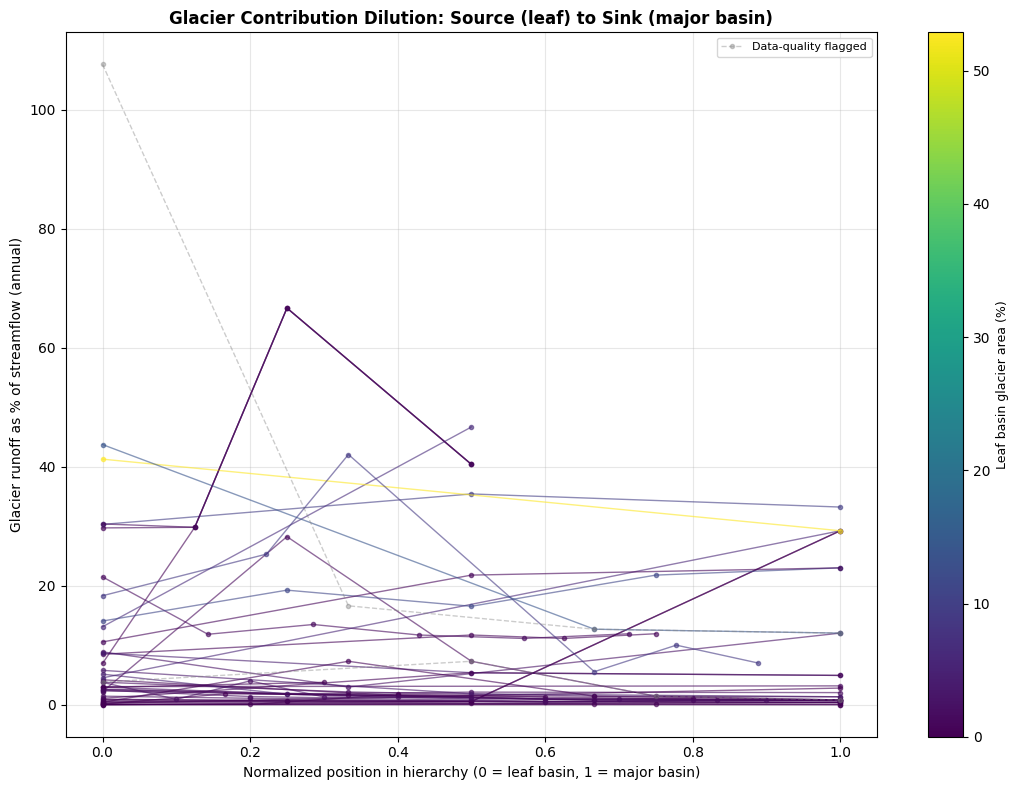

In [16]:
chain_records = []
for leaf_gid in leaf_glacierized_ids_v3:
    if leaf_gid not in RESULTS['CR2MET']:
        continue
    chain = get_full_chain(leaf_gid, container_map, area_by_id)
    n_levels = len(chain)
    for depth_idx, gid in enumerate(chain):
        row = bounds_all[bounds_all['gauge_id'] == gid]
        if len(row) == 0:
            continue
        chain_records.append({
            'leaf_gauge_id': leaf_gid, 'chain_position': depth_idx, 'chain_length': n_levels,
            'gauge_id': gid, 'area_km2': row['area_km2'].values[0],
            'annual_fraction_pct': basin_fraction(gid),
            'leaf_flagged': leaf_gid in flagged_basins,
        })

df_chains = pd.DataFrame(chain_records)
df_chains['normalized_position'] = df_chains.apply(
    lambda row: row['chain_position'] / (row['chain_length'] - 1) if row['chain_length'] > 1 else 0, axis=1)
df_chains.to_csv(f'{OUTPUT_ROOT}/basin_chain_fractions.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 8))
clean_chains = df_chains[~df_chains['leaf_flagged']]
flagged_chains = df_chains[df_chains['leaf_flagged']]

leaf_glacier_pct = {
    gid: glacier_area_by_gauge.get(gid, 0) / bounds_all[bounds_all['gauge_id'] == gid]['area_km2'].values[0] * 100
    for gid in leaf_glacierized_ids_v3 if len(bounds_all[bounds_all['gauge_id'] == gid]) > 0
}
max_pct = max(leaf_glacier_pct.values()) if leaf_glacier_pct else 1
cmap = plt.cm.viridis
norm = Normalize(vmin=0, vmax=max_pct)

for leaf_gid in clean_chains['leaf_gauge_id'].unique():
    sub = clean_chains[clean_chains['leaf_gauge_id'] == leaf_gid].sort_values('normalized_position')
    sub = sub.dropna(subset=['annual_fraction_pct'])
    if len(sub) < 2:
        continue
    color = cmap(norm(leaf_glacier_pct.get(leaf_gid, 0)))
    ax.plot(sub['normalized_position'], sub['annual_fraction_pct'], 'o-', color=color, alpha=0.6, lw=1, ms=3)

first_flagged = True
for leaf_gid in flagged_chains['leaf_gauge_id'].unique():
    sub = df_chains[df_chains['leaf_gauge_id'] == leaf_gid].sort_values('normalized_position')
    sub = sub.dropna(subset=['annual_fraction_pct'])
    if len(sub) < 2:
        continue
    ax.plot(sub['normalized_position'], sub['annual_fraction_pct'], 'o--', color='grey', alpha=0.4, lw=1, ms=3,
            label='Data-quality flagged' if first_flagged else None)
    first_flagged = False

sm = ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Leaf basin glacier area (%)', fontsize=9)
ax.set_xlabel('Normalized position in hierarchy (0 = leaf basin, 1 = major basin)', fontsize=10)
ax.set_ylabel('Glacier runoff as % of streamflow (annual)', fontsize=10)
ax.set_title('Glacier Contribution Dilution: Source (leaf) to Sink (major basin)', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/dilution_normalized.png', dpi=150, bbox_inches='tight')
plt.show()


### B4. Tier comparison: mean/median glacier fraction by cluster, all four tiers

The core decision table: Leaflet vs Level 1 up vs Level 2 up vs Major, national and by cluster
(CR2MET, uncleaned leaf set). This is what the basin-grouping-level decision was based on.

Mean glacier fraction (%) by cluster and tier:
tier     Leaflet  Level 1 up  Level 2 up  Major
cluster                                        
OT3          3.0         3.0         3.0    3.0
DA1         14.9        12.4        12.4   11.5
DA2         13.6        13.6        13.6   13.6
DA3          3.5         3.5         4.3    4.3
WA1          2.6         2.6         2.6    2.7
WA2          2.3         2.1         2.0    2.3
WA3          0.9         0.7         NaN    NaN
WA4          7.5        18.3        13.9   11.1
WA6         14.0        30.6        30.6    9.8

Median glacier fraction (%) by cluster and tier:
tier     Leaflet  Level 1 up  Level 2 up  Major
cluster                                        
OT3          3.0         3.0         3.0    3.0
DA1          8.5         8.5         8.5    9.0
DA2         13.6        13.6        13.6   13.6
DA3          0.4         0.4         4.3    4.3
WA1          2.6         2.6         2.5    2.6
WA2          0.9         0.5         0.

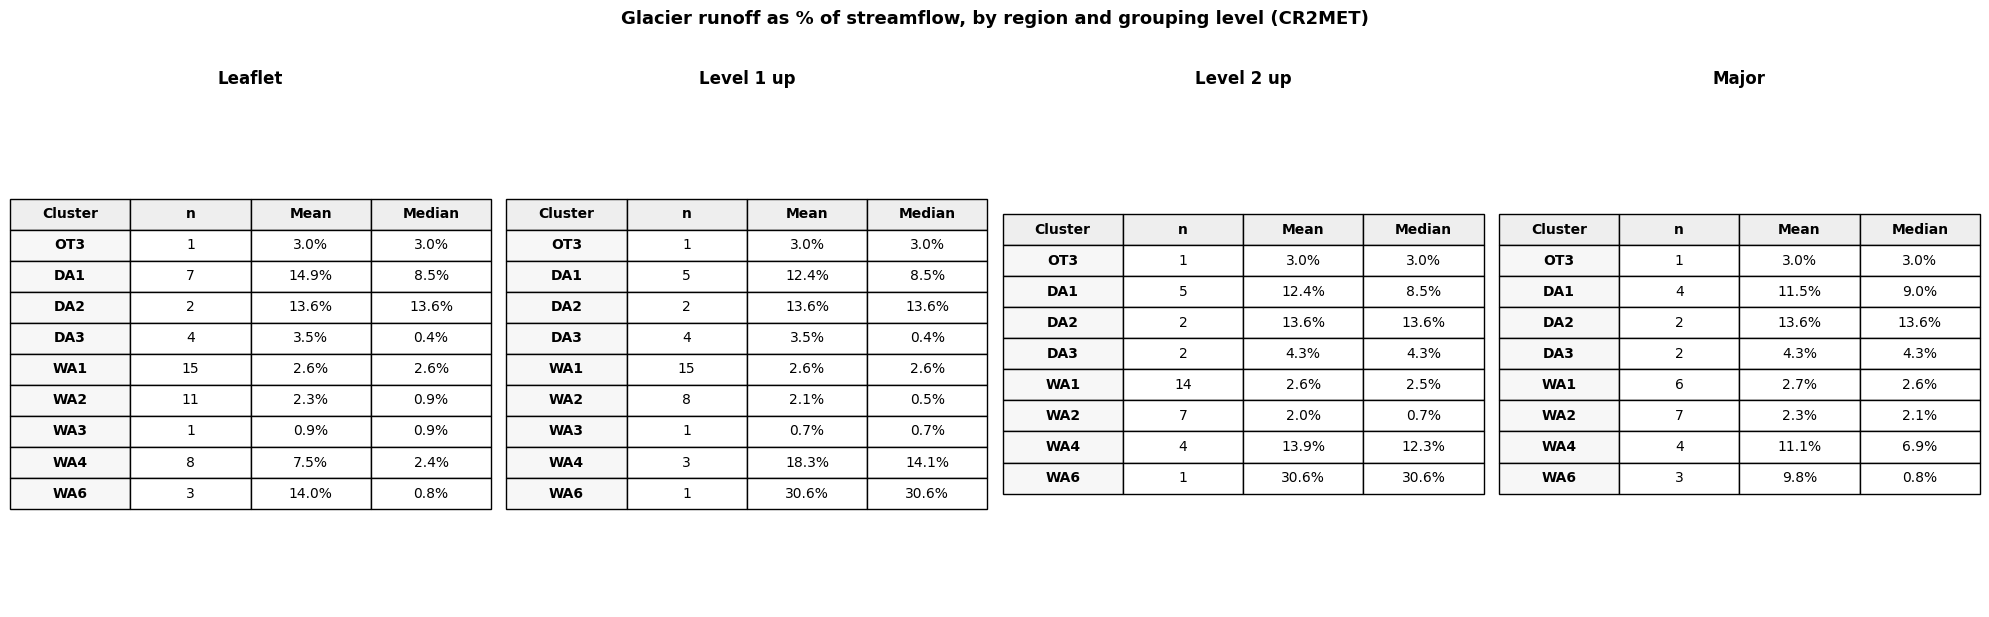

In [17]:
rows = []
for tier_name, gmap in tier_maps.items():
    groups = defaultdict(set)
    for leaf_id, grp_id in gmap.items():
        groups[grp_id].add(leaf_id)
    for grp_id, leaves in groups.items():
        frac = compute_pooled_fraction(leaves, dataset='CR2MET')
        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)
        rows.append({'tier': tier_name, 'gauge_id': grp_id, 'gauge_name': grp_name,
                      'n_leaves_pooled': len(leaves), 'glacier_pct': frac})
df_tiers = pd.DataFrame(rows)
df_tiers['cluster'] = df_tiers['gauge_id'].map(cluster_by_unit)

summary_by_cluster = (df_tiers.groupby(['cluster', 'tier'])['glacier_pct']
                       .agg(mean='mean', median='median', n_valid='count').reset_index())
cluster_order_list = [c for c in cluster_order if c in summary_by_cluster['cluster'].unique()] or \
                      sorted(df_tiers['cluster'].dropna().unique())

pivot_mean = summary_by_cluster.pivot(index='cluster', columns='tier', values='mean').reindex(cluster_order_list)[tier_order]
pivot_median = summary_by_cluster.pivot(index='cluster', columns='tier', values='median').reindex(cluster_order_list)[tier_order]
pivot_n = summary_by_cluster.pivot(index='cluster', columns='tier', values='n_valid').reindex(cluster_order_list)[tier_order]

print('Mean glacier fraction (%) by cluster and tier:')
print(pivot_mean.round(1).to_string())
print('\nMedian glacier fraction (%) by cluster and tier:')
print(pivot_median.round(1).to_string())
print('\nNumber of units by cluster and tier:')
print(pivot_n.to_string())

overall = df_tiers.groupby('tier')['glacier_pct'].agg(mean='mean', median='median', n_valid='count').reindex(tier_order)
print('\nOverall (all of Chile) by tier:')
print(overall.round(1).to_string())

tier_summary_tables = {t: summary_by_cluster[summary_by_cluster['tier'] == t][['cluster', 'n_valid', 'mean', 'median']].copy()
                       for t in tier_order}

fig, axes = plt.subplots(1, 4, figsize=(20, 0.5 * len(cluster_order_list) + 1.5))
for ax, tier_name in zip(axes, tier_order):
    ax.axis('off')
    table_data = make_table_data(prep(tier_summary_tables[tier_name]))
    tbl = ax.table(cellText=table_data, colLabels=['Cluster', 'n', 'Mean', 'Median'], loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.7)
    for i in range(4):
        tbl[(0, i)].set_facecolor('#eeeeee')
        tbl[(0, i)].set_text_props(fontweight='bold')
    for r in range(1, len(table_data) + 1):
        tbl[(r, 0)].set_facecolor('#f7f7f7')
        tbl[(r, 0)].set_text_props(fontweight='bold')
    ax.set_title(tier_name, fontsize=12, fontweight='bold', pad=12)
plt.suptitle('Glacier runoff as % of streamflow, by region and grouping level (CR2MET)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/basin_grouping_by_tier_table.png', dpi=200, bbox_inches='tight')
plt.show()


### B5. Own-gauge vs leaf-pooled comparison (tests Ale's compounding-error concern)

Compares each group's own gauge record to the leaf-pooled value, for every tier. This is the
check that found pooling does not compound error once bad gauges are screened out.

In [18]:
df_compare_level1 = compare_own_vs_pooled(level1_map, dataset='CR2MET')
df_compare_level2 = compare_own_vs_pooled(level2_map, dataset='CR2MET')
df_compare_major = compare_own_vs_pooled(major_map, dataset='CR2MET')

for name, df_c in [('Level 1', df_compare_level1), ('Level 2', df_compare_level2), ('Major', df_compare_major)]:
    both = df_c.dropna(subset=['own_fraction_pct', 'pooled_fraction_pct'])
    print(f'{name}: {len(both)} of {len(df_c)} groups have both an own record and a pooled value; '
          f'mean |diff| = {both["diff_own_minus_pooled"].abs().mean():.2f} pct pts')

print()
print('Level 1 units with their own gauge record:')
print(df_compare_level1[df_compare_level1['has_own_gauge_record']]
      .sort_values('pooled_fraction_pct', ascending=False).to_string(index=False))


Level 1: 26 of 70 groups have both an own record and a pooled value; mean |diff| = 4.92 pct pts
Level 2: 26 of 59 groups have both an own record and a pooled value; mean |diff| = 4.11 pct pts
Major: 20 of 41 groups have both an own record and a pooled value; mean |diff| = 1.43 pct pts

Level 1 units with their own gauge record:
gauge_id                                       gauge_name  n_leaves_pooled  has_own_gauge_record  own_n_valid_months  own_fraction_pct  pooled_fraction_pct  diff_own_minus_pooled
12289001                     Rio Serrano En Desembocadura                3                  True               224.0         29.233939            30.600328              -1.366389
11710000             Rio Pascua En Desague Lago O'Higgins                1                  True               146.0         35.419461            30.298306               5.121155
 3430003                          Rio Copiapo En Pastillo                3                  True               226.0         29.81701

### B6. Cleaned tier comparison (post bad-gauge exclusion/masking)

Same as B4 but using `tier_maps_clean` / `compute_pooled_fraction_clean` -- i.e. after applying
the exclude/mask decision from A11.

In [19]:
rows = []
for tier_name, gmap in tier_maps_clean.items():
    groups = defaultdict(set)
    for leaf_id, grp_id in gmap.items():
        groups[grp_id].add(leaf_id)
    for grp_id, leaves in groups.items():
        frac = compute_pooled_fraction_clean(leaves, dataset='CR2MET')
        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)
        rows.append({'tier': tier_name, 'gauge_id': grp_id, 'gauge_name': grp_name,
                      'n_leaves_pooled': len(leaves), 'glacier_pct': frac})
df_tiers_clean = pd.DataFrame(rows)
df_tiers_clean['cluster'] = df_tiers_clean['gauge_id'].map(cluster_by_unit_clean)

overall_clean = df_tiers_clean.groupby('tier')['glacier_pct'].agg(mean='mean', median='median', n_valid='count').reindex(tier_order)
print('Overall (all of Chile) by tier, after excluding bad gauges and masking bad months:')
print(overall_clean.round(1).to_string())

cluster_order_list_clean = [c for c in cluster_order if c in df_tiers_clean['cluster'].dropna().unique()] or \
                            sorted(df_tiers_clean['cluster'].dropna().unique())
summary_by_cluster_clean = (df_tiers_clean.groupby(['cluster', 'tier'])['glacier_pct']
                             .agg(mean='mean', median='median', n_valid='count').reset_index())
pivot_mean_clean = summary_by_cluster_clean.pivot(index='cluster', columns='tier', values='mean').reindex(cluster_order_list_clean)[tier_order]
print('\nMean glacier fraction (%) by cluster and tier, after cleaning:')
print(pivot_mean_clean.round(1).to_string())


Overall (all of Chile) by tier, after excluding bad gauges and masking bad months:
            mean  median  n_valid
tier                             
Leaflet      4.9     2.4       49
Level 1 up   5.5     3.0       39
Level 2 up   5.8     3.0       36
Major        5.7     3.0       29

Mean glacier fraction (%) by cluster and tier, after cleaning:
tier     Leaflet  Level 1 up  Level 2 up  Major
cluster                                        
OT3          3.0         3.0         3.0    3.0
DA1          6.6         6.6         6.6    5.0
DA2         13.6        13.6        13.6   13.6
DA3          3.5         3.5         4.3    4.3
WA1          2.5         2.5         2.5    2.7
WA2          2.3         2.1         2.0    2.3
WA3          0.9         0.7         NaN    NaN
WA4          7.5        18.2        13.8   11.0
WA6         14.0        30.5        30.5    9.8


### B7. Level 1 (cleaned): all years / megadrought / JFM windows, national and by cluster

Confirms the central Chile megadrought (2010-2019) increased the relative importance of
glacier melt, especially in WA1.

In [20]:
def build_level1_fraction_table(years=None, months=None, dataset='CR2MET'):
    groups = defaultdict(set)
    for leaf_id, grp_id in level1_map_clean.items():
        groups[grp_id].add(leaf_id)
    rows = []
    for grp_id, leaves in groups.items():
        frac = compute_pooled_fraction_clean(leaves, dataset=dataset, months=months, years=years)
        grp_name = bounds_all.loc[bounds_all['gauge_id'] == grp_id, 'gauge_name']
        grp_name = grp_name.values[0] if len(grp_name) else str(grp_id)
        rows.append({'gauge_id': grp_id, 'gauge_name': grp_name, 'n_leaves_pooled': len(leaves), 'glacier_pct': frac})
    return pd.DataFrame(rows)

df_level1_all_years = build_level1_fraction_table()
df_level1_megadrought = build_level1_fraction_table(years=MEGADROUGHT_YEARS)
df_level1_jfm = build_level1_fraction_table(months=JFM_MONTHS)

for df_w in [df_level1_all_years, df_level1_megadrought, df_level1_jfm]:
    df_w['cluster'] = df_w['gauge_id'].map(cluster_by_unit_clean)

summary_windows = pd.DataFrame({
    'All years': [df_level1_all_years['glacier_pct'].mean(), df_level1_all_years['glacier_pct'].median(), df_level1_all_years['glacier_pct'].notna().sum()],
    'Megadrought': [df_level1_megadrought['glacier_pct'].mean(), df_level1_megadrought['glacier_pct'].median(), df_level1_megadrought['glacier_pct'].notna().sum()],
    'JFM only': [df_level1_jfm['glacier_pct'].mean(), df_level1_jfm['glacier_pct'].median(), df_level1_jfm['glacier_pct'].notna().sum()],
}, index=['mean', 'median', 'n_valid'])
print('Level 1 (cleaned), national, glacier fraction of streamflow by analysis window:')
print(summary_windows.round(1).to_string())

cluster_order_list_clean = [c for c in cluster_order if c in df_level1_all_years['cluster'].dropna().unique()] or \
                            sorted(df_level1_all_years['cluster'].dropna().unique())
summary_all = cluster_summary(df_level1_all_years, cluster_order_list_clean)
summary_mega = cluster_summary(df_level1_megadrought, cluster_order_list_clean)
summary_jfm = cluster_summary(df_level1_jfm, cluster_order_list_clean)

combined_windows_by_cluster = pd.DataFrame({
    'All years mean': summary_all['mean'], 'Megadrought mean': summary_mega['mean'], 'JFM mean': summary_jfm['mean'],
    'n_valid': summary_all['n_valid'],
})
print('\nLevel 1 (cleaned), by cluster, mean glacier fraction by analysis window:')
print(combined_windows_by_cluster.round(1).to_string())


Level 1 (cleaned), national, glacier fraction of streamflow by analysis window:
         All years  Megadrought  JFM only
mean           5.5          6.2      14.3
median         3.0          3.5      13.7
n_valid       39.0         39.0      39.0

Level 1 (cleaned), by cluster, mean glacier fraction by analysis window:
         All years mean  Megadrought mean  JFM mean  n_valid
cluster                                                     
OT3                 3.0               3.6       9.7        1
DA1                 6.6               7.6      18.2        5
DA2                13.6              18.9      25.5        2
DA3                 3.5               4.4       7.1        4
WA1                 2.5               2.9      14.0       14
WA2                 2.1               2.1       5.5        8
WA3                 0.7               0.7       2.7        1
WA4                18.2              18.0      35.1        3
WA6                30.5              30.5      28.6        1


### B8. Basin overlap diagnostic (Level 1 units) -- DIAGNOSTIC ONLY, nothing dropped

**Read this before touching the numbers.** An earlier pass here treated geometric overlap
between Level 1 basins as data double-counting and dropped 22 "redundant" nested units from
national/regional aggregates. That was wrong and has been retracted: each Level 1 unit's own
glacier fraction is computed only from the leaf gauges explicitly assigned to it via
`level1_map` (a strict partition, one leaf -> exactly one Level 1 parent). Nothing outside that
assigned leaf set ever enters the calculation, so a basin's polygon nesting inside another
basin's polygon has no bearing on whether its own number double-counts anything. Cumulative
watershed delineation nests by construction; that is not a bug to fix.

The real open question this overlap DOES raise is representativeness / pseudoreplication: when
a river has multiple sequential gauges (e.g. Rio Copiapo En Lautaro upstream of Rio Copiapo En
Pastillo), do both deserve equal weight in a national or cluster mean, or should one stand in
for the reach? That is a judgment call, not a data bug, and it is **not resolved here** -- decide
it with Ale before it affects the paper's headline numbers.

In [21]:
level1_unit_ids = sorted(set(level1_map_clean.values()))
level1_geoms_utm = bounds_all[bounds_all['gauge_id'].isin(level1_unit_ids)][['gauge_id', 'gauge_name', 'geometry']].to_crs(epsg=32719)
level1_geoms_utm['area_km2'] = level1_geoms_utm.geometry.area / 1e6

ids = level1_geoms_utm['gauge_id'].tolist()
geoms = level1_geoms_utm.set_index('gauge_id')['geometry']
areas = level1_geoms_utm.set_index('gauge_id')['area_km2']

overlap_rows = []
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        gid_a, gid_b = ids[i], ids[j]
        geom_a, geom_b = geoms[gid_a], geoms[gid_b]
        if not geom_a.intersects(geom_b):
            continue
        inter_area = geom_a.intersection(geom_b).area / 1e6
        if inter_area < 0.01:
            continue
        overlap_rows.append({
            'gauge_id_a': gid_a, 'name_a': bounds_all.loc[bounds_all['gauge_id'] == gid_a, 'gauge_name'].values[0],
            'gauge_id_b': gid_b, 'name_b': bounds_all.loc[bounds_all['gauge_id'] == gid_b, 'gauge_name'].values[0],
            'overlap_km2': inter_area, 'pct_of_a': inter_area / areas[gid_a] * 100, 'pct_of_b': inter_area / areas[gid_b] * 100,
        })

df_overlaps = pd.DataFrame(overlap_rows).sort_values('overlap_km2', ascending=False)
print(f'Level 1 unit pairs with real spatial overlap: {len(df_overlaps)} out of {len(ids) * (len(ids) - 1) // 2} possible pairs')
print(df_overlaps.head(20).to_string(index=False))

# Pairs where one basin is nearly entirely nested inside another (>90%) -- candidates for the
# representativeness question above, NOT for exclusion.
nearly_nested = df_overlaps[(df_overlaps['pct_of_a'] > 90) | (df_overlaps['pct_of_b'] > 90)]
print(f'\nPairs where one basin is >90% nested inside the other: {len(nearly_nested)} '
      f'(flagged for representativeness discussion with Ale, NOT dropped from any total)')


Level 1 unit pairs with real spatial overlap: 50 out of 2415 possible pairs
gauge_id_a                                           name_a gauge_id_b                                     name_b  overlap_km2   pct_of_a   pct_of_b
  11536004                 Rio Baker En Angostura Chacabuco   11542001                       Rio Baker En Colonia 16792.931257  99.959380  64.034947
  11530000               Rio Baker En Desague Lago Bertrand   11536004           Rio Baker En Angostura Chacabuco 16002.680435 100.000000  95.255438
  11530000               Rio Baker En Desague Lago Bertrand   11542001                       Rio Baker En Colonia 15995.997249  99.958237  60.996072
   2104013              Rio Loa En Vado Santa Barbara (Doh)    2110031                       Rio Loa En Angostura  5331.731050  99.963853  58.500846
  12289001                     Rio Serrano En Desembocadura   12289002       Rio Serrano En Desague Lago Del Toro  5287.767962  61.605625 100.000000
   8312000                 Rio

### B9. Deliverable for Alexis: `main_basins_for_alexis.shp` export

In [22]:
OUT_PATH_ALE = f'{OUTPUT_ROOT}/main_basins_for_alexis.shp'
GLAC_THRESHOLD_PCT = 1.0  # Alexis recommends 1% minimum glacier cover

joined = gpd.sjoin(gdf_rgi, bounds_all, how='inner', predicate='within')
glacierized_gauge_ids_export = set(joined['gauge_id'].unique())
glacier_stats = (joined.groupby('gauge_id')
                 .agg(n_glaciers=('RGIId', 'count'), glacier_area=('Area', 'sum'),
                      clusters=('Cluster', lambda x: list(x.unique())))
                 .reset_index())

main_basins_export = bounds_all[bounds_all['gauge_id'].isin(df_hierarchy[df_hierarchy['depth'] == 0]['gauge_id'])].copy()
main_glacierized_export = main_basins_export[main_basins_export['gauge_id'].isin(glacierized_gauge_ids_export)].copy()
main_glacierized_export = main_glacierized_export.merge(df_hierarchy[['gauge_id', 'depth']], on='gauge_id', how='left')

main_utm_export = main_glacierized_export.to_crs(epsg=32719)
main_utm_export['basin_area_km2'] = main_utm_export.geometry.area / 1e6
main_utm_export = main_utm_export.merge(glacier_stats, on='gauge_id', how='left')
main_utm_export['glacier_area_km2'] = main_utm_export['glacier_area'].fillna(0)
main_utm_export['glacier_pct'] = main_utm_export['glacier_area_km2'] / main_utm_export['basin_area_km2'] * 100

before = len(main_utm_export)
main_final = main_utm_export[main_utm_export['glacier_pct'] >= GLAC_THRESHOLD_PCT].copy()
print(f'Geometrically top-level basins with glaciers: {before}')
print(f'After {GLAC_THRESHOLD_PCT}% threshold: {len(main_final)} ({before - len(main_final)} removed)')

main_export = main_final.to_crs(epsg=4326)
keep_cols = [c for c in ['gauge_id', 'gauge_name', 'depth', 'n_glaciers', 'basin_area_km2',
                          'glacier_area_km2', 'glacier_pct', 'geometry'] if c in main_export.columns]
main_export[keep_cols].to_file(OUT_PATH_ALE)
print(f'Saved: {OUT_PATH_ALE}')


Geometrically top-level basins with glaciers: 41
After 1.0% threshold: 15 (26 removed)
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/main_basins_for_alexis.shp


### B10. Deliverable for Alexis: major-basin map with glacier-fraction pie-chart pullouts

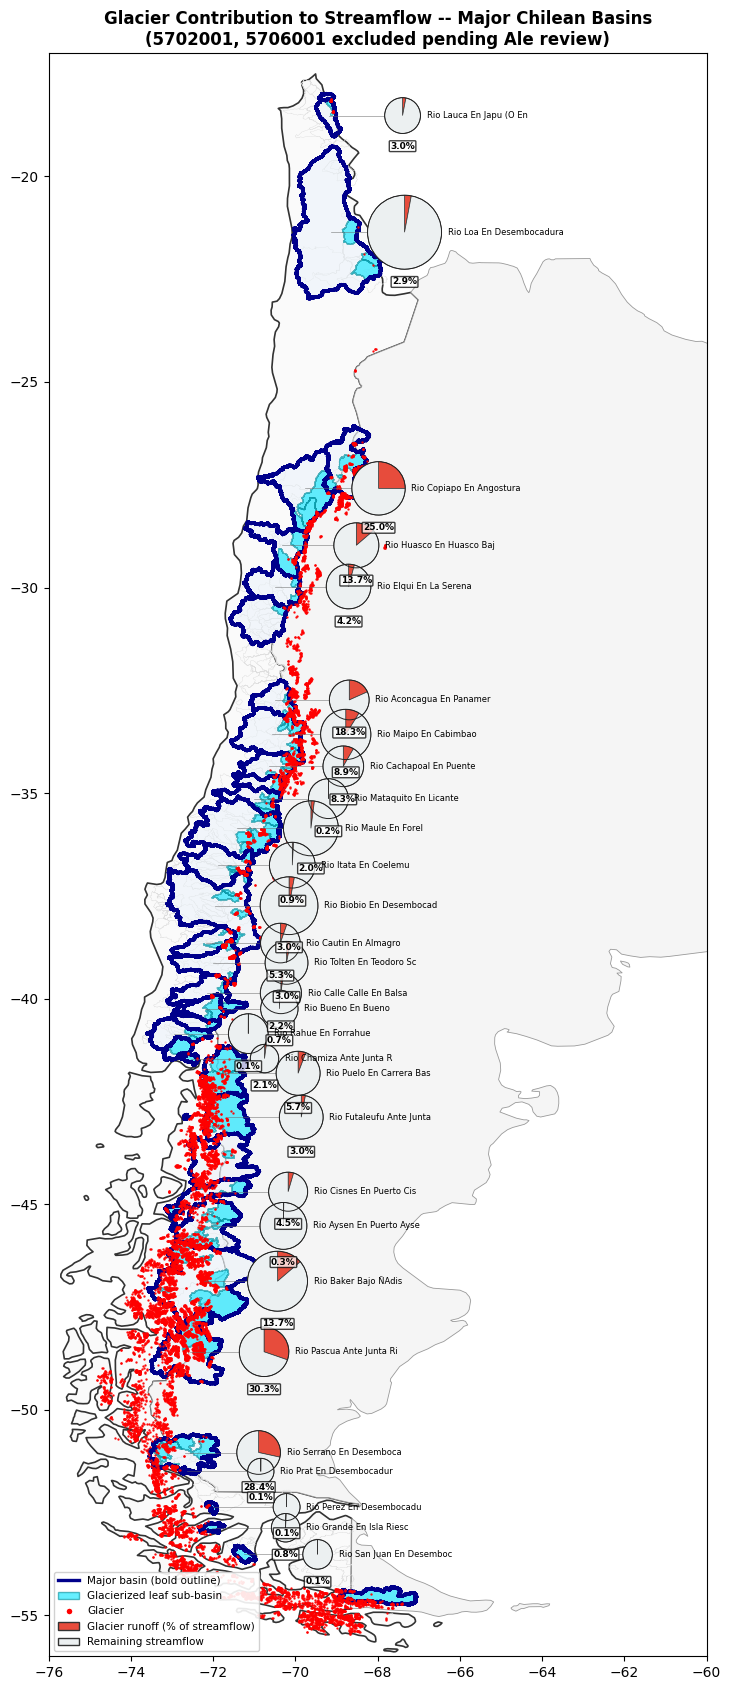

In [23]:
scope_results = {}
for _, major_row in df_glacierized_major.iterrows():
    mid = major_row['gauge_id']
    frac_annual, n_leaf = compute_leaf_fraction(mid, leaf_ids_final_clean)
    scope_results[mid] = {'annual_pct': frac_annual, 'n_leaf': n_leaf}

fig, ax = plt.subplots(figsize=(13, 17))
if has_borders:
    chile.plot(ax=ax, facecolor='#fafafa', edgecolor='#333333', linewidth=1.2, zorder=0)
    arg.plot(ax=ax, facecolor='#f5f5f5', edgecolor='#999999', linewidth=0.6, zorder=0)
bounds_all.plot(ax=ax, facecolor='none', edgecolor='#dddddd', linewidth=0.2, zorder=1)

glacierized_ids = set(df_glacierized_major['gauge_id'])
bounds_all[bounds_all['gauge_id'].isin(glacierized_ids)].plot(ax=ax, facecolor='#eaf2fa', alpha=0.5, edgecolor='none', zorder=2)
bounds_all[bounds_all['gauge_id'].isin(glacierized_ids)].plot(ax=ax, facecolor='none', edgecolor='#00008b', linewidth=2.4, zorder=4)
bounds_all[bounds_all['gauge_id'].isin(leaf_glacierized_ids_v3)].plot(ax=ax, facecolor='#00e5ff', alpha=0.6, edgecolor='#008b99', linewidth=0.7, zorder=3)

glacier_centroids = gpd.GeoSeries(rgi_geoms_combined.to_crs(epsg=32719).geometry.centroid, crs=32719).to_crs(epsg=4326)
ax.scatter(glacier_centroids.x, glacier_centroids.y, color='#ff0000', s=0.5, zorder=5, alpha=0.9)

has_scope = [g for g, r in scope_results.items() if not np.isnan(r['annual_pct'])]
df_pie = df_glacierized_major[df_glacierized_major['gauge_id'].isin(has_scope)].copy()
df_pie['centroid'] = df_pie['gauge_id'].apply(
    lambda g: bounds_all[bounds_all['gauge_id'] == g].geometry.centroid.values[0] if len(bounds_all[bounds_all['gauge_id'] == g]) else None)
df_pie = df_pie[df_pie['centroid'].notna()]
df_pie['cen_lat'] = df_pie['centroid'].apply(lambda c: c.y)
df_pie['frac_pct'] = df_pie['gauge_id'].map(lambda g: scope_results[g]['annual_pct'])

area_max = df_pie['area_km2'].max()
CIRC_MAX, CIRC_MIN = 0.9, 0.28
def area_to_radius(area):
    return CIRC_MIN if area <= 0 else CIRC_MIN + (area / area_max) ** 0.5 * (CIRC_MAX - CIRC_MIN)

LABEL_OFFSET = 1.8
for _, row in df_pie.sort_values('cen_lat', ascending=False).iterrows():
    cx, cy = row['centroid'].x, row['centroid'].y
    label_x = cx + LABEL_OFFSET
    radius = area_to_radius(row['area_km2'])
    frac = row['frac_pct']
    ax.plot([cx, label_x], [cy, cy], color='#666666', lw=0.5, zorder=6, alpha=0.7)
    frac_clip = min(frac / 100, 1.0)
    theta1 = 90
    for size, fc in [(frac_clip, '#e74c3c'), (1 - frac_clip, '#ecf0f1')]:
        theta2 = theta1 - size * 360
        ax.add_patch(Wedge((label_x, cy), radius, min(theta1, theta2), max(theta1, theta2), facecolor=fc, edgecolor='#333333', lw=0.5, zorder=7))
        theta1 = theta2
    ax.add_patch(plt.Circle((label_x, cy), radius, facecolor='none', edgecolor='#222222', lw=0.7, zorder=8))
    ax.text(label_x, cy - radius - 0.2, f'{frac:.1f}%', ha='center', va='top', fontsize=6.5, fontweight='bold', zorder=9,
            bbox=dict(boxstyle='round,pad=0.1', facecolor='white', alpha=0.75))
    ax.text(label_x + radius + 0.15, cy, row['gauge_name'][:24], fontsize=6, va='center', ha='left', zorder=9)

legend_elements = [
    Line2D([0], [0], color='#00008b', lw=2.4, label='Major basin (bold outline)'),
    Patch(facecolor='#00e5ff', edgecolor='#008b99', alpha=0.6, label='Glacierized leaf sub-basin'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#ff0000', markersize=5, label='Glacier'),
    Patch(facecolor='#e74c3c', edgecolor='#333333', label='Glacier runoff (% of streamflow)'),
    Patch(facecolor='#ecf0f1', edgecolor='#333333', label='Remaining streamflow'),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=7.5, framealpha=0.9)
ax.set_title('Glacier Contribution to Streamflow -- Major Chilean Basins\n(5702001, 5706001 excluded pending Ale review)',
             fontsize=12, fontweight='bold')
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/major_basins_pie_glacier_fraction_for_Ale.png', dpi=200, bbox_inches='tight')
plt.show()


### B11. Country-scale maps: final unit sets vs major basins

Three maps at true national geographic scale (not small multiples): the 16 leaves with no
intermediate against their major basins, the Level 1 final unit set (intermediate + major
substitute, green) against major outlines (red dashed), and the one-level-up version.

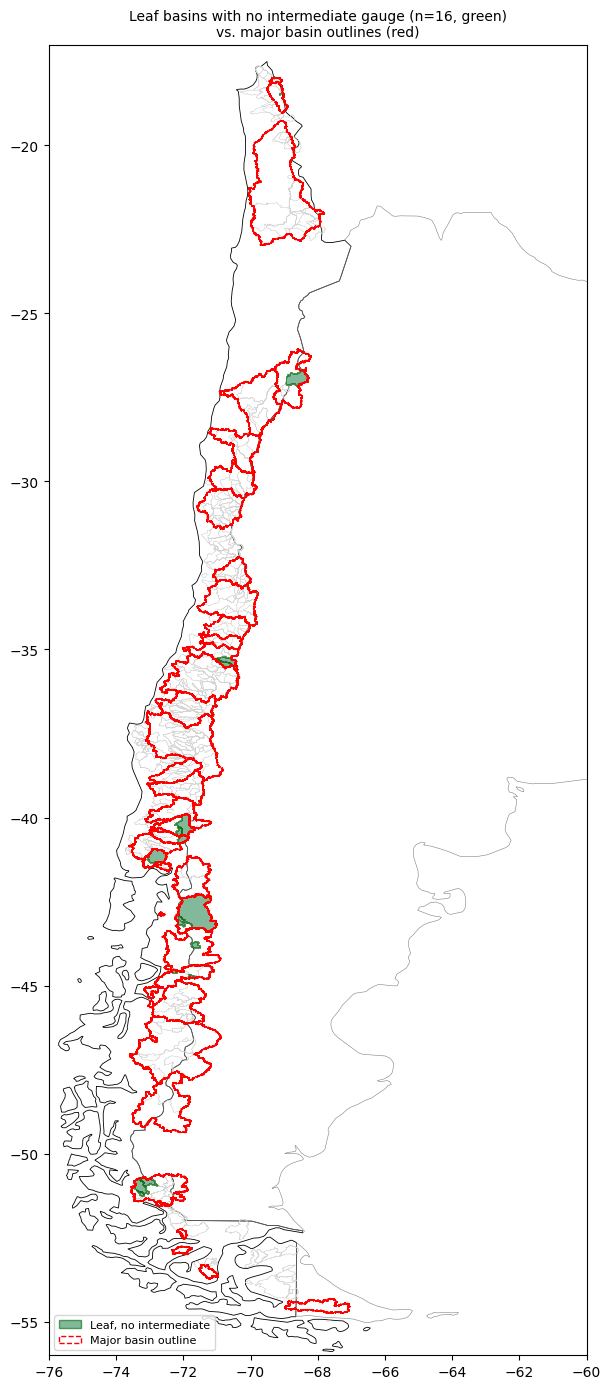

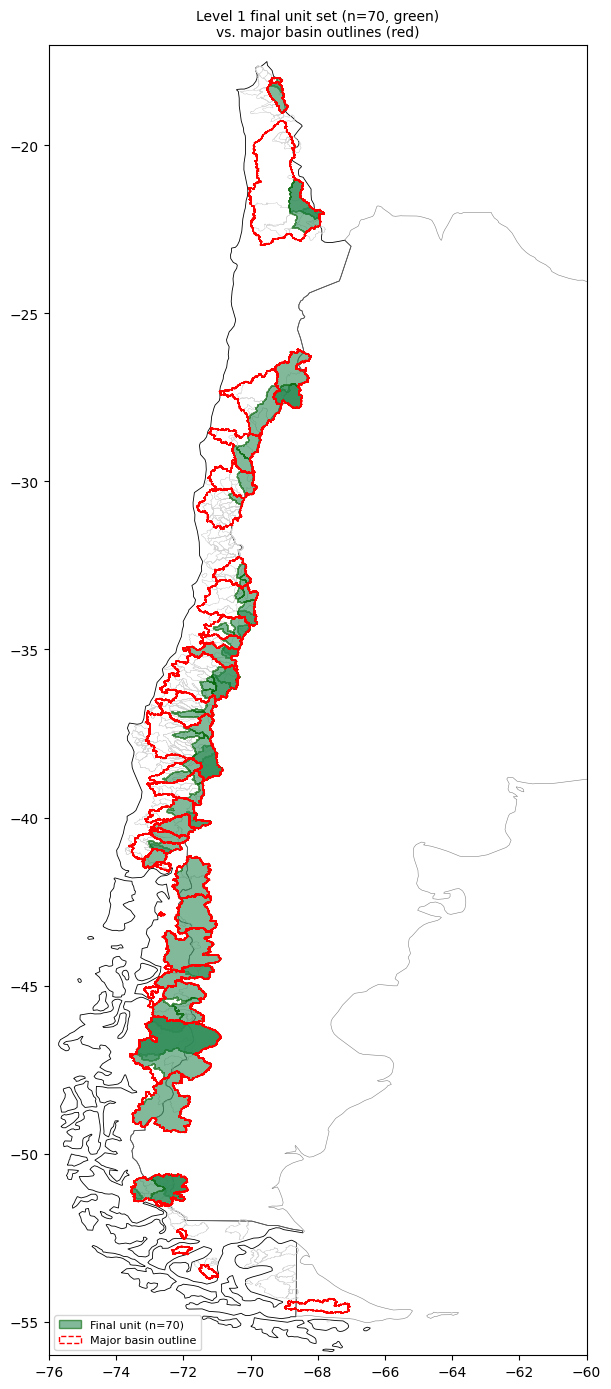

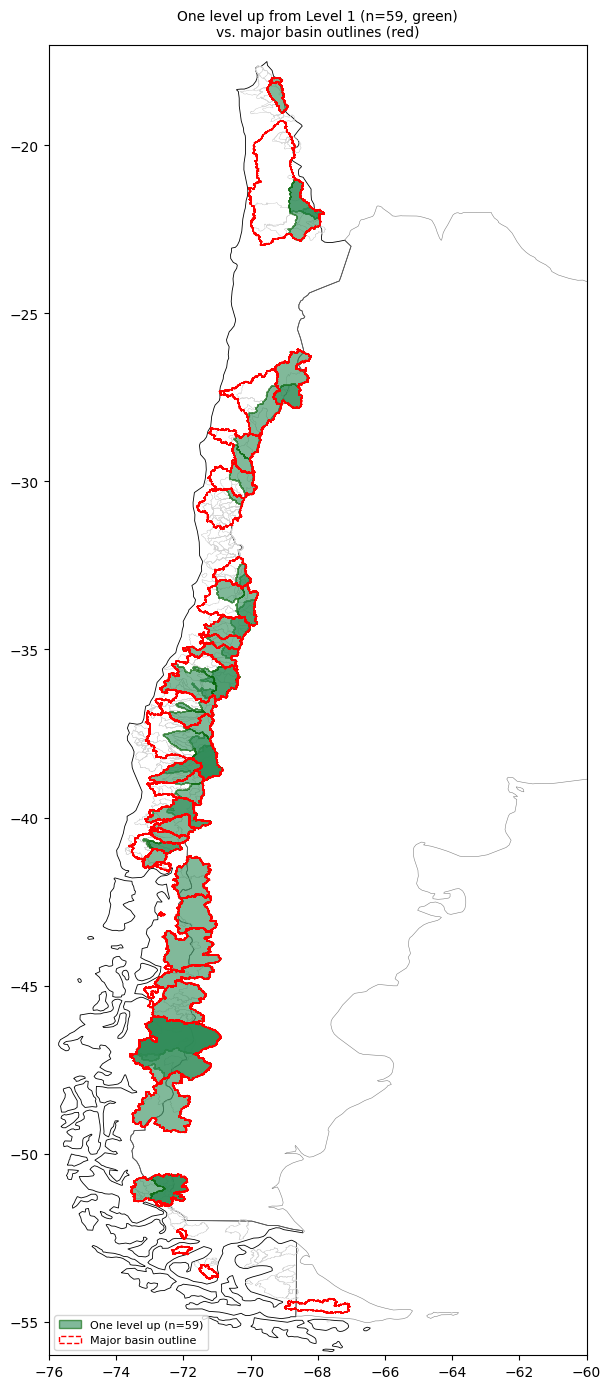

In [24]:
# Map 1: the 16 leaves with no intermediate gauge, plotted against their major basins
fig, ax = plt.subplots(figsize=(9, 14))
chile.boundary.plot(ax=ax, color='black', linewidth=0.6)
if has_borders:
    arg.boundary.plot(ax=ax, color='gray', linewidth=0.4)
bounds_all.boundary.plot(ax=ax, color='lightgray', linewidth=0.3)

no_intermediate_leaf_ids = set(jump_to_major_ids.keys())
bounds_all[bounds_all['gauge_id'].isin(no_intermediate_leaf_ids)].plot(
    ax=ax, color='seagreen', alpha=0.6, edgecolor='darkgreen', linewidth=0.7, zorder=3)
bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])].boundary.plot(
    ax=ax, color='red', linewidth=1.1, linestyle='--', zorder=4)
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')
ax.set_title(f'Leaf basins with no intermediate gauge (n={len(no_intermediate_leaf_ids)}, green)\nvs. major basin outlines (red)', fontsize=10)
ax.legend(handles=[Patch(facecolor='seagreen', alpha=0.6, edgecolor='darkgreen', label='Leaf, no intermediate'),
                    Patch(facecolor='none', edgecolor='red', linestyle='--', label='Major basin outline')], loc='lower left', fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/leaves_no_intermediate_vs_major.png', dpi=300, bbox_inches='tight')
plt.show()

# Map 2: final Level 1 unit set (intermediate + major substitute)
fig, ax = plt.subplots(figsize=(9, 14))
chile.boundary.plot(ax=ax, color='black', linewidth=0.6)
if has_borders:
    arg.boundary.plot(ax=ax, color='gray', linewidth=0.4)
bounds_all.boundary.plot(ax=ax, color='lightgray', linewidth=0.3)
bounds_all[bounds_all['gauge_id'].isin(final_unit_ids)].plot(ax=ax, color='seagreen', alpha=0.6, edgecolor='darkgreen', linewidth=0.7, zorder=3)
bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])].boundary.plot(ax=ax, color='red', linewidth=1.1, linestyle='--', zorder=4)
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')
ax.set_title(f'Level 1 final unit set (n={len(final_unit_ids)}, green)\nvs. major basin outlines (red)', fontsize=10)
ax.legend(handles=[Patch(facecolor='seagreen', alpha=0.6, edgecolor='darkgreen', label=f'Final unit (n={len(final_unit_ids)})'),
                    Patch(facecolor='none', edgecolor='red', linestyle='--', label='Major basin outline')], loc='lower left', fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/final_unit_set_intermediate_plus_major.png', dpi=300, bbox_inches='tight')
plt.show()

# Map 3: one level up from the Level 1 set
fig, ax = plt.subplots(figsize=(9, 14))
chile.boundary.plot(ax=ax, color='black', linewidth=0.6)
if has_borders:
    arg.boundary.plot(ax=ax, color='gray', linewidth=0.4)
bounds_all.boundary.plot(ax=ax, color='lightgray', linewidth=0.3)
bounds_all[bounds_all['gauge_id'].isin(unique_next_level_ids)].plot(ax=ax, color='seagreen', alpha=0.6, edgecolor='darkgreen', linewidth=0.7, zorder=3)
bounds_all[bounds_all['gauge_id'].isin(df_glacierized_major['gauge_id'])].boundary.plot(ax=ax, color='red', linewidth=1.1, linestyle='--', zorder=4)
ax.set_xlim(-76, -60); ax.set_ylim(-56, -17); ax.set_aspect('equal')
ax.set_title(f'One level up from Level 1 (n={len(unique_next_level_ids)}, green)\nvs. major basin outlines (red)', fontsize=10)
ax.legend(handles=[Patch(facecolor='seagreen', alpha=0.6, edgecolor='darkgreen', label=f'One level up (n={len(unique_next_level_ids)})'),
                    Patch(facecolor='none', edgecolor='red', linestyle='--', label='Major basin outline')], loc='lower left', fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/one_level_up_unit_set.png', dpi=300, bbox_inches='tight')
plt.show()


### B12. Substitute-gauge search for excluded basins (CORRECTED quality check)

For each systematically excluded gauge, walk downstream to find a usable substitute, now
correctly checking the CANDIDATE's own data quality via `classify_gauge` rather than just
whether it exists in `RESULTS`. **This is the cell that catches the 5406001 problem** -- rerun
this before telling Ale anything further about which substitutes are usable.

In [25]:
rows = []
for gid in sorted(exclude_gauge_ids):
    name = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name'].values[0]
    chain = walk_downstream(gid)
    final_step = chain[-1]
    rows.append({
        'excluded_id': gid, 'excluded_name': name, 'n_hops': len(chain),
        'final_status': final_step['status'],
        'final_gauge_id': final_step.get('gauge_id'), 'final_gauge_name': final_step.get('gauge_name'),
        'final_glacier_pct': final_step.get('glacier_pct'), 'final_n_valid_months': final_step.get('n_valid_months'),
    })
df_substitute_search = pd.DataFrame(rows)
print(df_substitute_search.to_string(index=False))

usable = df_substitute_search[df_substitute_search['final_status'].isin(['clean_has_record', 'mask_only'])]
print(f'\n{len(usable)} of {len(exclude_gauge_ids)} excluded gauges resolve to a usable substitute '
      f'after the corrected quality check.')
print('Compare this against any substitute list already sent to Ale -- 5406001 (Rio Colorado En '
      'Colorado), previously reported as a clean substitute for Aconcagua En Rio Blanco at ~9.5%, '
      'is NOT clean (42.2% of months with impossible glacier runoff) and needs a correction.')


excluded_id                               excluded_name  n_hops     final_status final_gauge_id                           final_gauge_name  final_glacier_pct  final_n_valid_months
    1020003               Rio Lauca En Estancia El Lago       2         dead_end           None                 NO PARENT FOUND (dead end)                NaN                   NaN
    3022001                     Rio La Ola En Vertedero       1         dead_end           None                 NO PARENT FOUND (dead end)                NaN                   NaN
    3414001                     Rio Pulido En Vertedero       5    no_own_record        3434001 Rio Copiapo En Mal Paso Aguas Arriba Canal                NaN                   NaN
    3421001                    Rio Manflas En Vertedero       5    no_own_record        3434001 Rio Copiapo En Mal Paso Aguas Arriba Canal                NaN                   NaN
    3430001                      Rio Copiapo En Lautaro       5    no_own_record        3450001     

### B13. Quality + hydrograph check on candidate substitute gauges (Ale's request)

Quality check on the candidate substitute gauges:
gauge_id                    gauge_name  n_valid_months  n_bad_months  pct_bad  mean_bad_ratio  max_bad_ratio       classification
 3820001       Rio Huasco En Algodones             218            21 9.633028        2.598171       6.331587 mask_bad_months_only
 7322001     Rio Maule En Longitudinal             234             0 0.000000             NaN            NaN                clean
 5410002 Rio Aconcagua En Chacabuquito             234             0 0.000000             NaN            NaN                clean


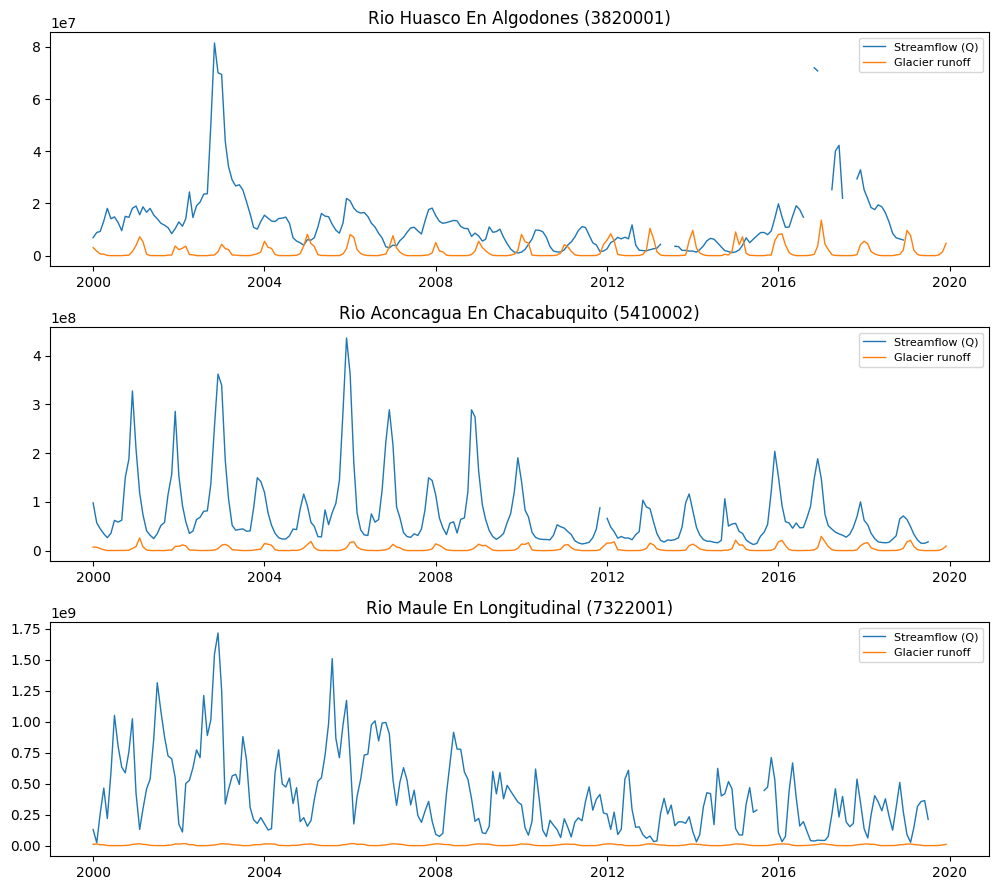

In [26]:
substitute_ids = sorted(set(
    df_substitute_search.loc[df_substitute_search['final_status'].isin(['clean_has_record', 'mask_only']), 'final_gauge_id']
))

df_substitute_quality = check_gauge_quality_v2(substitute_ids)
df_substitute_quality['classification'] = df_substitute_quality.apply(classify_gauge, axis=1)
print('Quality check on the candidate substitute gauges:')
print(df_substitute_quality.to_string(index=False))

fig, axes = plt.subplots(len(substitute_ids), 1, figsize=(10, 3 * len(substitute_ids)), sharex=False)
if len(substitute_ids) == 1:
    axes = [axes]
for ax, gid in zip(axes, substitute_ids):
    res = RESULTS['CR2MET'].get(gid)
    name = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name'].values[0]
    if res is None:
        ax.set_title(f'{name} ({gid}) - no data')
        continue
    m = res['monthly'].copy()
    m['date'] = pd.to_datetime(dict(year=m['year'], month=m['month'], day=1))
    m = m.sort_values('date')
    ax.plot(m['date'], m['q_m3_mon'], label='Streamflow (Q)', linewidth=1)
    ax.plot(m['date'], m['glacier_runoff_m3'], label='Glacier runoff', linewidth=1)
    ax.set_title(f'{name} ({gid})')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/substitute_gauges_hydrographs.png', dpi=150, bbox_inches='tight')
plt.show()


### B14. Hydrographs: own streamflow vs. glacier runoff for the dead ends and the unresolved Copiapo leaves

Two groups, plotted on their own gauge record (`RESULTS['CR2MET']`), for visual inspection before
deciding how to handle them:

- **True dead ends** (no parent basin found at all): Rio Lauca En Estancia El Lago (1020003),
  Rio La Ola En Vertedero (3022001), Rio Cachapoal En Pte Termas De Cauquenes (6008005),
  Rio Tinguiririca En Los Olmos (6035001).
- **Copiapo leaves with no confirmed clean substitute** (the corrected walk found their old
  stand-in, Rio Copiapo En La Puerta / 3431001, is itself bad quality, and nothing further
  downstream resolves within 5 hops): Rio Manflas En Vertedero (3421001), Rio Pulido En Vertedero
  (3414001), Rio Copiapo En Lautaro (3430001), Rio Copiapo En Pastillo (3430003).

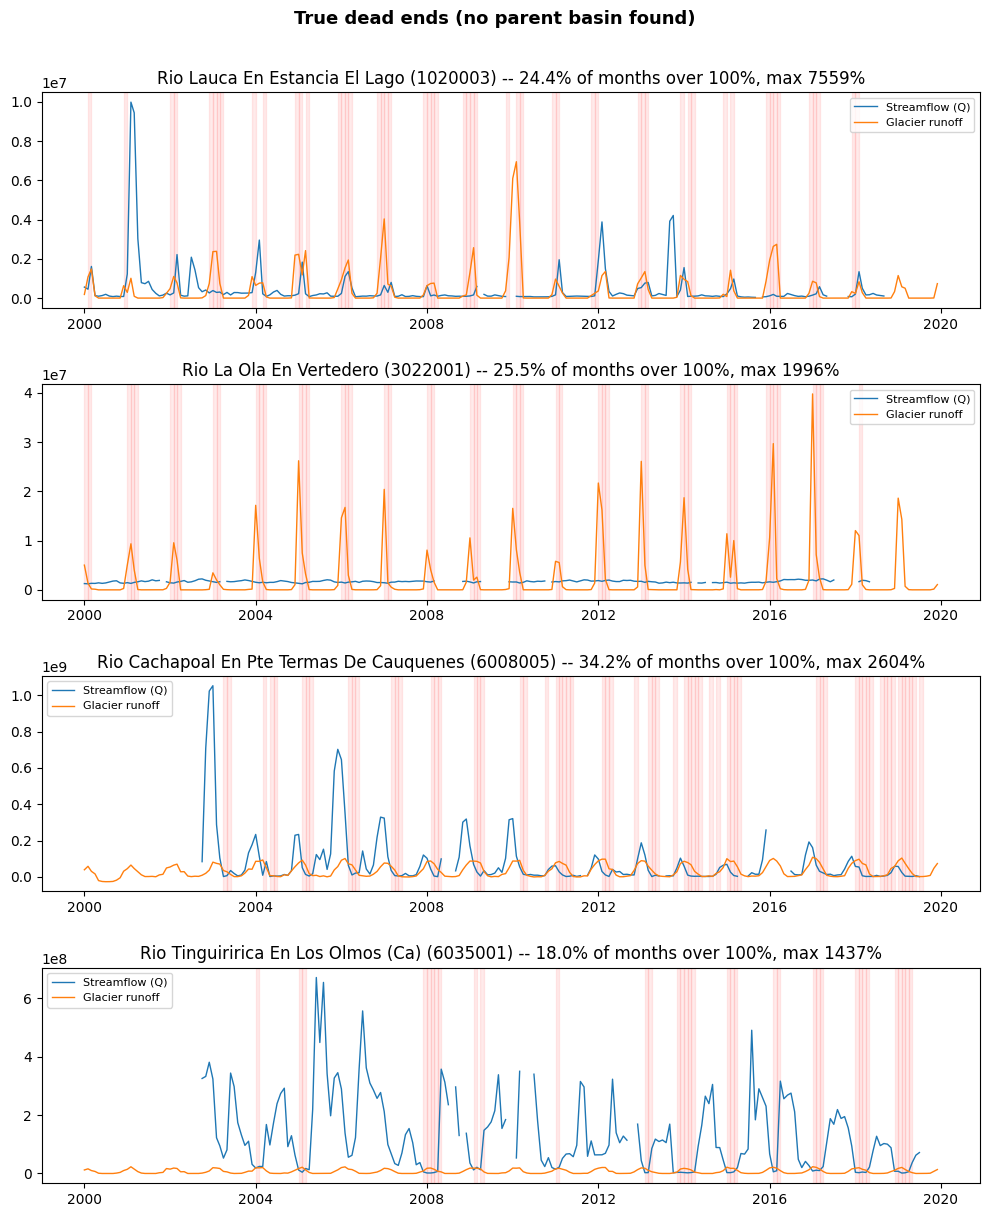

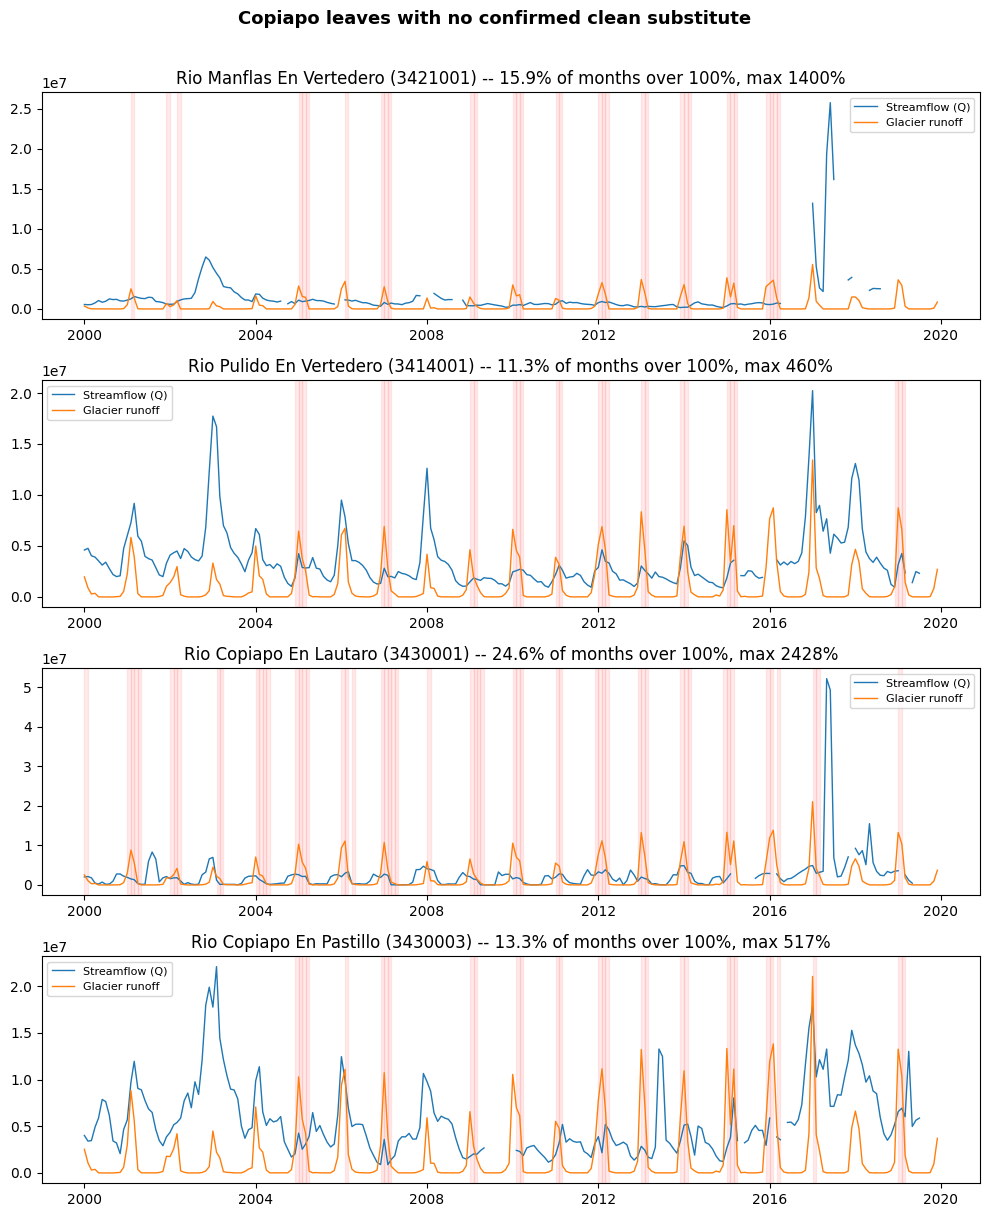

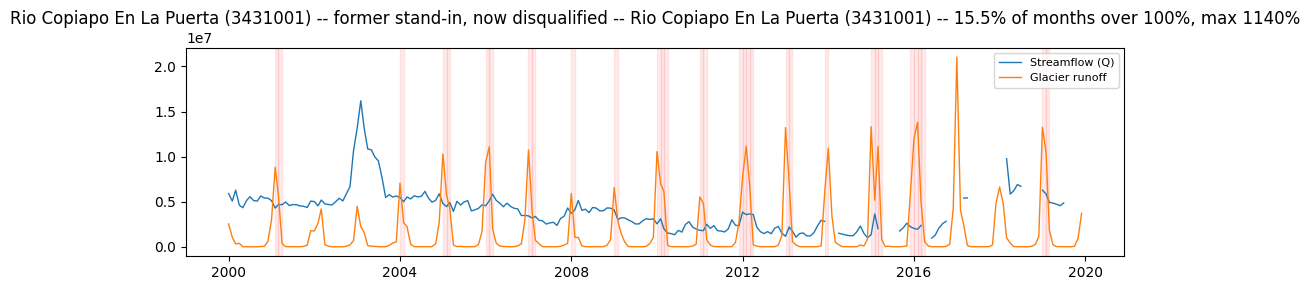

In [27]:
dead_end_ids = ['1020003', '3022001', '6008005', '6035001']
copiapo_unresolved_ids = ['3421001', '3414001', '3430001', '3430003']

def plot_own_hydrograph(ax, gid, dataset='CR2MET'):
    res = RESULTS[dataset].get(gid)
    name = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name']
    name = name.values[0] if len(name) else gid
    if res is None:
        ax.set_title(f'{name} ({gid}) - no data')
        return
    m = res['monthly'].copy()
    m['date'] = pd.to_datetime(dict(year=m['year'], month=m['month'], day=1))
    m = m.sort_values('date')
    ax.plot(m['date'], m['q_m3_mon'], label='Streamflow (Q)', linewidth=1)
    ax.plot(m['date'], m['glacier_runoff_m3'], label='Glacier runoff', linewidth=1)
    # shade months where glacier runoff exceeds Q, so the impossible months are visible at a glance
    bad = m[(m['q_m3_mon'] > 0) & (m['glacier_runoff_m3'] > m['q_m3_mon'])]
    for _, r in bad.iterrows():
        ax.axvspan(r['date'], r['date'] + pd.DateOffset(months=1), color='red', alpha=0.08, zorder=0)
    q_result = check_runoff_exceeds_q(gid, dataset=dataset)
    if q_result is not None:
        ax.set_title(f"{name} ({gid}) -- {q_result['pct_months_over_100']:.1f}% of months over 100%, "
                     f"max {q_result['max_pct']:.0f}%")
    else:
        ax.set_title(f'{name} ({gid}) - no valid Q months')
    ax.legend(fontsize=8)

fig, axes = plt.subplots(len(dead_end_ids), 1, figsize=(10, 3 * len(dead_end_ids)))
fig.suptitle('True dead ends (no parent basin found)', fontsize=13, fontweight='bold', y=1.01)
for ax, gid in zip(axes, dead_end_ids):
    plot_own_hydrograph(ax, gid)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/dead_end_gauges_hydrographs.png', dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(len(copiapo_unresolved_ids), 1, figsize=(10, 3 * len(copiapo_unresolved_ids)))
fig.suptitle('Copiapo leaves with no confirmed clean substitute', fontsize=13, fontweight='bold', y=1.01)
for ax, gid in zip(axes, copiapo_unresolved_ids):
    plot_own_hydrograph(ax, gid)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/copiapo_unresolved_gauges_hydrographs.png', dpi=150, bbox_inches='tight')
plt.show()

# also plot the disqualified former stand-in, Rio Copiapo En La Puerta (3431001), for reference --
# this is the gauge that used to be treated as a clean substitute for all four Copiapo leaves above
fig, ax = plt.subplots(figsize=(10, 3))
plot_own_hydrograph(ax, '3431001')
ax.set_title('Rio Copiapo En La Puerta (3431001) -- former stand-in, now disqualified -- ' + ax.get_title())
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/copiapo_la_puerta_disqualified_hydrograph.png', dpi=150, bbox_inches='tight')
plt.show()

Quality check on the candidate substitute gauges:
gauge_id                    gauge_name  n_valid_months  n_bad_months  pct_bad  mean_bad_ratio  max_bad_ratio       classification
 3820001       Rio Huasco En Algodones             218            21 9.633028        2.598171       6.331587 mask_bad_months_only
 7322001     Rio Maule En Longitudinal             234             0 0.000000             NaN            NaN                clean
 5410002 Rio Aconcagua En Chacabuquito             234             0 0.000000             NaN            NaN                clean


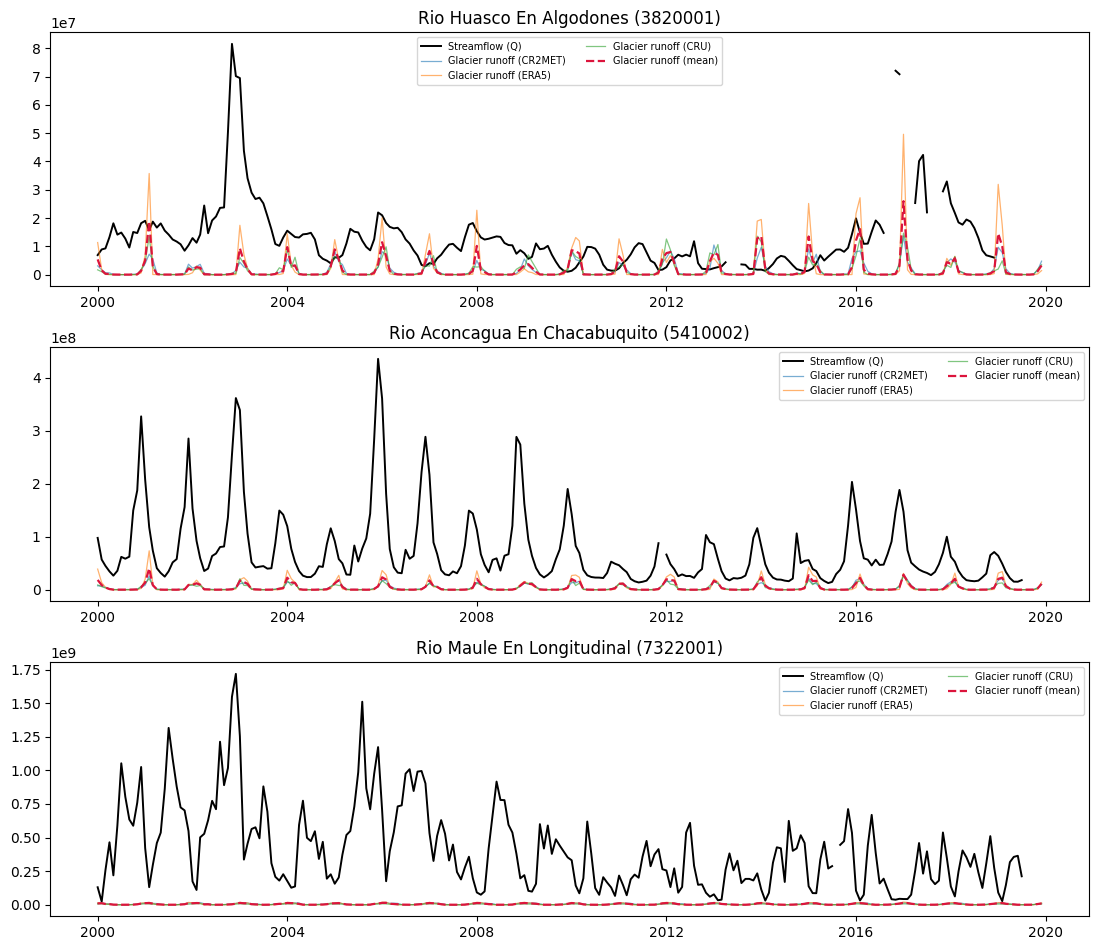

In [30]:
substitute_ids = sorted(set(
    df_substitute_search.loc[df_substitute_search['final_status'].isin(['clean_has_record', 'mask_only']), 'final_gauge_id']
))

df_substitute_quality = check_gauge_quality_v2(substitute_ids)
df_substitute_quality['classification'] = df_substitute_quality.apply(classify_gauge, axis=1)
print('Quality check on the candidate substitute gauges:')
print(df_substitute_quality.to_string(index=False))

datasets = ['CR2MET', 'ERA5', 'CRU']
dataset_colors = {'CR2MET': '#1f77b4', 'ERA5': '#ff7f0e', 'CRU': '#2ca02c'}

fig, axes = plt.subplots(len(substitute_ids), 1, figsize=(11, 3.2 * len(substitute_ids)), sharex=False)
if len(substitute_ids) == 1:
    axes = [axes]

for ax, gid in zip(axes, substitute_ids):
    name = bounds_all.loc[bounds_all['gauge_id'] == gid, 'gauge_name'].values[0]

    # streamflow: take from whichever dataset has it first (Q is the observed record, not simulated)
    q_series = None
    for ds in datasets:
        res = RESULTS[ds].get(gid)
        if res is not None:
            q_series = res['monthly'].copy()
            break
    if q_series is None:
        ax.set_title(f'{name} ({gid}) - no data')
        continue
    q_series['date'] = pd.to_datetime(dict(year=q_series['year'], month=q_series['month'], day=1))
    q_series = q_series.sort_values('date')
    ax.plot(q_series['date'], q_series['q_m3_mon'], label='Streamflow (Q)', linewidth=1.4, color='black')

    # glacier runoff: each dataset, plus the mean across whichever datasets have this gauge
    runoff_frames = []
    for ds in datasets:
        res = RESULTS[ds].get(gid)
        if res is None:
            continue
        m = res['monthly'].copy()
        m['date'] = pd.to_datetime(dict(year=m['year'], month=m['month'], day=1))
        m = m.sort_values('date')
        ax.plot(m['date'], m['glacier_runoff_m3'], label=f'Glacier runoff ({ds})',
                linewidth=0.9, alpha=0.6, color=dataset_colors[ds])
        runoff_frames.append(m.set_index('date')['glacier_runoff_m3'].rename(ds))

    if runoff_frames:
        runoff_wide = pd.concat(runoff_frames, axis=1)
        runoff_mean = runoff_wide.mean(axis=1)
        ax.plot(runoff_mean.index, runoff_mean.values, label='Glacier runoff (mean)',
                linewidth=1.6, color='crimson', linestyle='--')

    ax.set_title(f'{name} ({gid})')
    ax.legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/substitute_gauges_hydrographs_all_datasets.png', dpi=150, bbox_inches='tight')
plt.show()

In [31]:
gid = '5406001'  # or whichever gauge is in question
res = RESULTS['CR2MET'][gid]['monthly']
glacier_area_m2 = glacier_area_by_gauge.get(gid, 0) * 1e6  # km2 -> m2
implied_melt_mm = res['glacier_runoff_m3'] / glacier_area_m2 * 1000
print(implied_melt_mm.describe())

count    240.000000
mean      82.630060
std      115.464928
min        0.977648
25%        6.015214
50%       22.964842
75%      124.859264
max      589.322994
Name: glacier_runoff_m3, dtype: float64
